# UTS Sains Data — EDA awal, penanganan, dan hasil akhir
**Aprilia Dwi Cristyana — 1226800011**

Notebook ini dijalankan ulang dari citra dan label mentah, bukan membaca statistik
EDA historis sebagai hasil baru. Input konfigurasi berupa split tetap, keputusan
review 28 pasangan, 37 relabel dan satu penghapusan box; tidak ada citra yang dikeluarkan.

Sumber lokal RSGM UNAIR/Paramita sesuai keterangan pengguna, ditambah Kaggle.
Outlier dipertahankan karena kondisi nyata citra dan gigi. Targetnya deteksi
bounding box dan enumerasi 20 kelas FDI gigi susu; bukan prediksi umur.

**Jalankan semua cell berurutan.** Cell pipeline menghitung ulang dari sumber
dan mengekspor hasil. Tidak memakai cache. Citra dan label asli tidak ditimpa.

Lokasi sumber: `MyDrive/1226800011_Aprilia_UjianEDA_Revisi`. Hasil disimpan pada `hasil_analisis`. ZIP ekspor YOLO asli diekstrak otomatis jika folder berlabel belum tersedia. Jalankan **Runtime → Run all**, lalu izinkan mount Google Drive saat diminta.


In [2]:
# Cell 1 — dependensi. Tidak memasang ulang jika sudah tersedia.
import importlib.util, subprocess, sys
packages = {'numpy':'numpy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
            'scipy':'scipy', 'yaml':'pyyaml', 'matplotlib':'matplotlib', 'PIL':'pillow'}
missing = [pipname for mod,pipname in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Dependensi tersedia.')


Dependensi tersedia.


In [3]:
# Lokasi Drive sesuai folder yang diberikan pengguna.
from pathlib import Path, PurePosixPath
import os, json, hashlib, unicodedata, zipfile, shutil

PROJECT_NAME = '1226800011_Aprilia_UjianEDA_Revisi'
YOLO_FOLDER = 'enumerasi gigi susu6-252-.v1i.yolov11'
YOLO_ZIP = 'enumerasi_gigi_susu_252_label_asli.zip'

def normal_name(value):
    return ' '.join(unicodedata.normalize('NFKC', value).split()).casefold()

def get_project_root():
    try:
        from google.colab import drive
    except ImportError:
        # Hanya untuk verifikasi lokal. Di Colab, lokasi default tetap /content/drive.
        pass
    else:
        drive.mount('/content/drive')
    mydrive = Path(os.environ.get('FDI_MYDRIVE', '/content/drive/MyDrive'))
    direct = mydrive / PROJECT_NAME
    if direct.is_dir():
        return direct
    if not mydrive.is_dir():
        raise FileNotFoundError('Drive belum tersedia. Jalankan notebook ini di Google Colab dan izinkan akses Drive.')
    matches = [p for p in mydrive.iterdir()
               if p.is_dir() and normal_name(p.name) == normal_name(PROJECT_NAME)]
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Folder {PROJECT_NAME!r} belum ditemukan secara unik pada {mydrive}. '
            'Pastikan akun saat mount Drive adalah akun pemilik folder tersebut. '
            f'Kandidat: {matches}'
        )
    return matches[0]

def yolo_is_complete(root):
    images = root / 'train' / 'images'
    labels = root / 'train' / 'labels'
    if not ((root / 'data.yaml').is_file() and images.is_dir() and labels.is_dir()):
        return False
    paths = [p for p in images.iterdir()
             if p.is_file() and p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}]
    return len(paths) == 252 and all((labels / (p.stem + '.txt')).is_file() for p in paths)

def get_raw_yolo(project_root):
    unpacked = project_root / YOLO_FOLDER
    if yolo_is_complete(unpacked):
        print('Ekspor YOLO asli:', unpacked)
        return unpacked
    archive = project_root / YOLO_ZIP
    if not archive.is_file():
        raise FileNotFoundError(
            f'Ekspor YOLO dengan label FDI belum tersedia. Letakkan {YOLO_ZIP} '
            f'atau folder {YOLO_FOLDER} pada {project_root}. '
            'Empat folder sumber saja belum memuat label FDI yang diperlukan.'
        )
    digest = hashlib.sha256()
    with archive.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    scratch = Path(os.environ.get('FDI_SCRATCH', '/content'))
    extracted = scratch / ('fdi_raw_' + digest.hexdigest()[:12])
    root = extracted / YOLO_FOLDER
    if not yolo_is_complete(root):
        extracted.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            if z.testzip() is not None:
                raise RuntimeError('ZIP belum lengkap atau rusak. Tunggu unggahan selesai lalu jalankan ulang.')
            for info in z.infolist():
                rel = PurePosixPath(info.filename)
                if rel.is_absolute() or '..' in rel.parts or chr(92) in info.filename:
                    raise ValueError('ZIP memiliki lokasi file yang tidak aman.')
                if ((info.external_attr >> 16) & 0o170000) == 0o120000:
                    raise ValueError('ZIP dengan symbolic link tidak digunakan.')
                target = (extracted / Path(*rel.parts)).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError('Lokasi ekstraksi keluar dari folder tujuan.')
            z.extractall(extracted)
    if not yolo_is_complete(root):
        raise RuntimeError('Ekspor YOLO harus memuat data.yaml, 252 citra dan pasangan file label aslinya.')
    print('ZIP YOLO diekstrak otomatis ke penyimpanan lokal runtime:', root)
    return root

PROJECT_ROOT = get_project_root()
print('Folder proyek Drive:', PROJECT_ROOT)

BASE_UTS = PROJECT_ROOT
RAW_YOLO = get_raw_yolo(PROJECT_ROOT)
required = [
    'DENTAL DATASET PARAMITA 2016-2018',
    'Data terpilih dari Dental Paramita 11-12',
    'Dataset PARAMITA 2026',
    'Childrens dental caries segmentation dataset_KAGEL',
]
for name in required:
    if not (PROJECT_ROOT / name).is_dir():
        raise FileNotFoundError(f'Folder sumber belum tersedia: {PROJECT_ROOT/name}')
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / 'hasil_analisis' / 'mpl_cache')
print('Semua folder sumber tersedia.')


Mounted at /content/drive
Folder proyek Drive: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi
ZIP YOLO diekstrak otomatis ke penyimpanan lokal runtime: /content/fdi_raw_fd36b5351138/enumerasi gigi susu6-252-.v1i.yolov11
Semua folder sumber tersedia.


In [4]:
# Input keputusan review dan split penelitian, disimpan sebagai konfigurasi.
import io
UTS_OUT=BASE_UTS/'hasil_analisis'
UTS_OUT.mkdir(exist_ok=True)
CONFIG_INPUTS={'split_tetap.csv': 'image_id,filename,split,group_id,file_sha256,label_sha256\nIMG0001,0031-BEAUTY-AN-5TH_jpg.rf.4030e6326d4102644a020b352c1e5c5b.jpg,valid,0,80ac635d3d55b1592cf069dadf4dfc872b2003e47717a6b9514ce886faba5e3e,a47e1dca3ca4581c0ea8a0ee35be9205f7b7db971b1555c9286563ccefe9e146\nIMG0002,0049-LINTANG-AN-8TH_jpg.rf.3b93a454c0020be984332ddda7665cc9.jpg,train,1,1160231b7bf138094ada92e4fee16c3c1affafe9919092989117241fd9861605,fe66557663e667d25a153caaa1692456aa0e763f4fae63ffbaa2c0c8f96831ca\nIMG0003,0056-MICHAEL-AN-9TH_jpg.rf.a01f64b1743841e6bc9dd248a07d35de.jpg,train,2,19ae8db523e184bc50d67cf3464c3e45e2f5bd738a87bfd4669b5df128f6ab46,8540f4b451d632bb6c8a9f312e88ae311c66d445c182d9b715bb36ae02c7d0f8\nIMG0004,0061-ALTHAMIS-AN-7TH_jpg.rf.3d1d6a685cb7c981b3bdeb3777a75e52.jpg,train,3,741cd04b0a97d7a23c49483b9380d9942bc186c2095a6dd9fdc74293c9408c37,29a13745a1dfdced8bcc53473af82e361b93861c1de59250a90c96ea84c3bd90\nIMG0005,0107-SHEVA-AN-7TH_jpg.rf.b35a0dbaa51557ea916d801fb594c820.jpg,train,4,f3a46388d38083d611815e2ca1e872876eb3b026b29cd3dc9c088a2e6e4b36ad,689f51da640e4e2d887eb0fc696f35d73c8c09dbd594167b80e26a470e9811c1\nIMG0006,0147-diky-an-9-thn_jpg.rf.998a4a45f57021ec121dab42fd9a993a.jpg,train,5,913719d9ec2b095f7b397dcb19e7bae1f848422c5e0fc108953eac82c2cea1f6,d0fbe2afd7a9d182d10255cd74221ee2fd3ee49efbda3787ec95f437c89ba740\nIMG0007,0164-ARKAAN-AN-8TH_jpg.rf.ff9edf5a5f7565d33a407d1216f86145.jpg,train,6,5e5f20f5285850da52a53144b7e4173569307391b69828f8f044ea8b17ffca31,b2df13dccda9cd783d3a7e74abb687b6dc9ca07a90b5537ca14d40cc371e0e53\nIMG0008,0171-JAVIER-AN-10TH_jpg.rf.a9de23846f39ce81705dacc2dad07b45.jpg,test,7,4627a051bc8165ce16c675e0aa361938451394a9a87d85f1b0b405b8a865b910,d6ba9606ba435d42138cf6e9c9d7e2b386592bba957175509314e7b82450084d\nIMG0009,0175-PUTRI-A-AN-10TH_jpg.rf.cb893c38ad920eaff5850915c8c01893.jpg,test,8,908aa9ba271b2c885c76d713e002c64426f266b6ab199de1d3b869fa2fd79173,12fc150abe9ac40cc9966a908a3305c0e64e2cb9bd66382ba98c7eb0cbf27dbc\nIMG0010,0275-DAVINA-AN-7TH_jpg.rf.326576b83f5d95c3e4f46c92e2dd40f2.jpg,train,9,0f350dc5d847a07efd29a79f9d75fb808a9796937cdee1e65b23c69defbadac5,0d4299eae691f8c644cb0308781f6541ea3ce2d32e87356d5147dcc93c6f134e\nIMG0011,039-AXEL-AN-8TH_jpg.rf.11e494fe059f6f4db140dc971b02d8dd.jpg,train,10,8c6cc216176357ccf891d206179615e9f11a0665903854821dd457cc67014e78,af251520075036b9408c8861affa54e57ea8053ccda930a2a00af8943d25f5eb\nIMG0012,041-CAKA-AN-9TH_jpg.rf.5dee337f84b7331350d570f54bd97877.jpg,train,11,903f3e4808be7d2c589774abfa1135a66812f037ef454e518d1253e3e2d9ad64,07db2abc38454899bd021dd6de62f1bd7ef00c60a7d9d69b92843f5b29e07d7d\nIMG0013,0417-ABU-BAKAR-AN-7TH_jpg.rf.f8aa383fee6a9d87398b969e4ea21b1f.jpg,train,12,dae23a8d6beaa525e13e90c92ce8e5d65ec739f39200d2d63fa637acc0d770d9,eb57b41a8212bc4c83252464018cd64355da7e1e7a0b59d900424aa537d63f5f\nIMG0014,0469-ANINDYA-AN-6TH_jpg.rf.eeefc80b698e75e02cd8ee5a2d98528f.jpg,valid,13,7f399b77afcac818ec8d0740681617de03b2e101425a3de70517e482ee3405ce,08a02c8b46b356d14df8b27b0fb075751809eea49471a532a81c823a8b9ac343\nIMG0015,0680-AHMAD-HILMAN-AN-5TH_jpg.rf.ed1c203e74d59763321a8e38ddbbbc0b.jpg,valid,14,ae8f262a74fe43e4edea507ce42b59039ba00a6fc51a47faa311bc08ca573d67,5f329c78f18a8b3e6dabc445bd1e11738d2111b129d3c056ffa811b96443137d\nIMG0016,0910-NISRINA-KAMILIA-AN-7TH_jpg.rf.3fda76712456a025513a97979986b0aa.jpg,train,15,639d6f5aa40672af11e8b2a3cd2d32e2f325b5b9632499bd42901e41401cf9db,9a54c78132b3b4f3bfe36a0afaa3ec6ec2bb2239dba7c81719cb2aa2c0d2ae37\nIMG0017,1004-AMIRA-AN-6TH_jpg.rf.1e764a199cd8bafbd13340ad9c901afd.jpg,train,16,a88203dae47159df4b42202c3db9386ca5fb26bc7fc86c69baf423b7a39b142e,16957a196ddd0bb8bc8d0345534a75532fc1f847ffc7bfaae81ca7fc240ed177\nIMG0018,1022-anelka-safakila-7-thn_jpg.rf.829bc11f6484db1514a0dafee5c68814.jpg,test,17,530da7cf7ccbd40cc7727e3a79ddb8a663d5148b34df7fcfb5af214260779cbd,3bb8bf250194a6c54242521b9f59a1c05a1b74bdbd78b740314025135765eb28\nIMG0019,1055-FAREL-S-8TH_jpg.rf.0e7912129ae381288c35c7abbba92602.jpg,train,18,bf3a39ac42aba334baa47761526948db3c925e51abb736a183e267dd79c0c8c4,53188b5dd99aed9c34c844edd349898101242874fb7a5e9260ac7282d7348a11\nIMG0020,1070-MIRZA-A-5-THN_jpg.rf.c03250d5d1f1dbe02c170ae0d2747694.jpg,train,19,b01a2baa7f2a30cce49aad3bdaf7956b819b4547ea2e24a167ea5cd2d379327c,e9c1eff4029858c539b61f1451745ff4b808005cf560b3e7dcb6e5036d807299\nIMG0021,1085-M-RIZQI-AN-10-TH_jpg.rf.b1015210b8135733daab3a993feaa1ac.jpg,train,20,5e74bca4eceb16e6b76cc7179e2c8abaeb40786947d1fbef815bff3453aadb50,e3fcd39747c52dcb594ae6b4856ee0ac3e4fc2df0195c57ee2934282688ef3f1\nIMG0022,1102-felah-7-thn_jpg.rf.13b6e16df50d2e5f96ca33d06dc9e5b6.jpg,train,21,8d05f80c706e26f5922830a29b511379198fb6f0ee0b3fb3a650f0f0f49cf382,e9310beda2dc5c7480ec52b55bcbb9bb7816f5ffdcb36296ccd89274dbae5ef3\nIMG0023,1123-DEVINA-AN-10TH_jpg.rf.1978d4a25c0151babd8940ed4b34070a.jpg,train,22,46289dce51df1e4e233ba33d01c8bd3f44f131118f1db52222fe3601d6aa76cc,78375009464cb50429378260277db201ad499a0917bb713620af6f9bae1c5798\nIMG0024,1131-RIMA-AN-8TH_jpg.rf.826e4fdb86b771fe72a88d9e0cc929c4.jpg,valid,23,3095fcdda2dd522749ad279e739f1a405f55786e139d2abaed4062d1a18f15cf,8b82ba9fef5dbb81a370cea7de9eae9dff01802d81903355649299956b14567e\nIMG0025,1178-TITANIA-AN-5TH_jpg.rf.baadc73a2ff937019fa34afe1d1bad4a.jpg,train,24,db58eee4f3c565abefc2244e44f9cd3cde50d414f3c9a091be52c57e908b6ac3,86ac1c4ad68f15cb434a79efbbe55ba3e9eee805a5ddc1bf1eb3437e92634361\nIMG0026,1221-APRILIA-KUSUMA-12TH_jpg.rf.10e9037c3f0b145f70c53313cf3369d6.jpg,valid,25,14e70f0f591e246f04e69dced618ed6d89dbec584ab03ea522a9a1f1a50678f7,c4fce4d9bb4bf4d5b1f762732bef341349f1c2002d405ce4ca5f35355a6f9bd8\nIMG0027,1230-VIORENTINA-AN-9-TH_jpg.rf.5e1bf09892c30830557620ec125089d6.jpg,train,26,c8d42f52df59c5fbbbdc270c6e35d9324fba0a15dfea2893aec15fc428d74c68,928a9e3bcfc833cf0d5c85764a44dfc622656877e014429fd3c2c99528dc0d77\nIMG0028,1246-BARA-AN-4TH_jpg.rf.f30e7f314ac85964fec00db414d05fd1.jpg,train,27,1632c0ebc823e61469618824e4de26f4303a6b0d3107300b7e156b875a0fbc80,90a2b5be327928411c3055d2d927a65884a87fbb66c4fdca8c0677c78a1dd5bd\nIMG0029,1253-ALFARO-5-THN_jpg.rf.a821ef5f0c49efead727ea04ce10bb15.jpg,valid,28,4c793116a082cda7030d8314dde2154a9c57c1909d693bb96ea5568f466548b2,77451ce60f7c2c54cd62a8b38fd07fc0dd170a3fa6dda8631cc6982d133c3d9c\nIMG0030,1260-RIFDA-AN-8TH_jpg.rf.0f671a82557bd6d159012d8d81acb2ba.jpg,train,29,de2498c6191fb2e2921acb7a9cb52a61355a8ac95949c4c0b853821850dd1981,bd7d6b147cb7bdad5193b5a552002a665cb2a7bf8e73eafb6a6f7b7de4f1dc6a\nIMG0031,1268-M-ZABIBUL-4-THN_jpg.rf.a8ee815510029cec7781623d61bc4347.jpg,train,30,152d76f02ddb4cea68bdd523680d296616cf37771bba10555d36e37f3f5e7c58,e8adf9546f9123695595ea39096697ec3b87bc67509e8ec6a31fe070b167574b\nIMG0032,1276-WIDYA-6TH_jpg.rf.2c047a28ce0e69c0443469c1a55a85ba.jpg,train,31,15138e6d211311a78d3e96d3c96ff3b00191ee1a969936f231cddef2a1c6dd16,41d35512592ea1dfb7a5bad65887d612cb76201f0c74e48e678e6b3add42c091\nIMG0033,1295-YUDIO-AN-10TH_jpg.rf.cc7f8f16056641fbba41d48867dacb2f.jpg,train,32,f6d67afebe9716319e1159aa80f5fb7efc0f49cfca30bb458fd0d95f6d8a0900,e57b443f5e82c54fe02e7633f755579d75878a7ae530e0a4e8862919b47d6bd8\nIMG0034,1331-DIN-MALIK-AN-6TH_jpg.rf.9b44cc983f04035e5565b35d67ab9b3e.jpg,valid,33,77a2ab7b238cbc6149b54c61d8c785540dac6a46f35d06542c7b69b4747e5117,76138db8cb282bc08b1f71bbd8d993aa774dd39dde07cd91bb5f4978dab0823b\nIMG0035,1332-shafa-4-thn_jpg.rf.2e8d1c1ab73a0ebd437d7b5ba723e659.jpg,train,34,069d11f527c67445bc609229c58fdce4298bc9dea8777bae1358c9852fd62556,31b0e9beb6f32a34901a07bd8d21b4b229e3bb83cda97348e9b438db44d4b74f\nIMG0036,1345-JERICHO-AN-7-THN_jpg.rf.29640614f22083643963d5070cca1795.jpg,train,35,bf8709f2b6a9e7710f41f89c7b8bd742fe9a1fe33ff70edfd3f2ad7e4fbf2bae,cb7e98aa323aeeb03bc0f443d7f1bed41728fd3f091c66e65585dbcdedb5c430\nIMG0037,1369-KEISHA-9-THN_jpg.rf.8da8dfe74419955f1b87c88bb255e1a3.jpg,train,36,3d73167958eee2f1106c0ab2faf2f074292bd454da7c80572a9b3bda4ec4a6d7,adfed0fbafedbb4a30ddf6279a82a13497f970016eab87f123ddb578c0bf22b9\nIMG0038,1409-AGNES-AN-9TH_jpg.rf.2fa278798e7e0a655f72f088f19f5ac4.jpg,train,37,6a038f4a895a73039b19f19de0f4c9eca1ca4848b77796a9029f08f0761170e8,0cd749de2779ea74d27015cc37a8e960f22205faeaf9ce9d178e823b355ebcc6\nIMG0039,1429-M-ARIF-8-THN_jpg.rf.63c3eb57fc9fe42163ca42a3663c3a78.jpg,train,38,1876ec2b8112c2a9e71f83432292c7f97e6795e7d80dd079d4155b50b6fba8a3,73f03b9bf0e50272f9e7a8a78f62f4cb4f188cfeb30ec37c265c7632a48bff63\nIMG0040,1432-KINANTI-AN-10TH_jpg.rf.a0d51e8df4e14deca9b9a0cc162f2255.jpg,valid,39,90b1b71034b50454434469499e8dffa4f370ccde1472f51c053e8904435c7c05,c2bf5e37d6a079e465a3f522630974837962816bfd6722eede0b7d37fce4bab9\nIMG0041,1438-M-ABSYAR-6TH_jpg.rf.8286be044b875267da667811dfaceaad.jpg,test,40,e4e2bf8c77e3b732ea24dbef78b9b415510129658df62639aa3eb01974c878ed,ef21125f50af1b527b8243770e11aa019a713f627899dc1dcad1c59e0a3d7faf\nIMG0042,1445-M-FARDHAN-9TH_jpg.rf.d4cd8e024fd668e0bf79f6de9aefee9e.jpg,train,41,147985b15efc34a294c90896b54f31d120e0dfec477a4650f24b0c51b49cd44b,b05cc1e2d0c2af61722c5e5f5b6c8eebcbad73f5d82e1b6a6ef3166d5201b543\nIMG0043,1453-PRATAMA-7TH_jpg.rf.58115a4990f30ba210dd32ae664a6f20.jpg,train,42,232904a34b2fe0282f1777a5154abacfc24e43798a3a1173c44bc563c79058d8,7c935d9ecd31d21b0f8acaead7fcc4db9dd1c37f9439bd76c20d0bb23b6575f1\nIMG0044,146-athalia-8-thn_jpg.rf.f3e8da355cae12ed2025166130f94262.jpg,valid,43,ecee28ca5174f1e915580e70c4c486c6e9f8193d7a22ffb07f48c6115c184be2,dd7ec94865678d541ab73a7e6c54cd54e05dba7ed38ce2923a3a5ea0177b2726\nIMG0045,1471-sultan-10-thn_jpg.rf.a1fa0d1a8afd1a2a752de8eae25d3655.jpg,valid,44,99340a08ece487951b7c32be07e69c975a4c4989ac33d95ccbc0af3e0646fa79,7c464a1c4e1afcefbc6f2a015e8e3fb859f8fc625a8169a034406e816b0c8b12\nIMG0046,1473-ALDY-AN-7-THN_jpg.rf.9c287af61c7149c10e9221e4472573fb.jpg,train,45,955e80214baaee118d8d6bbbb0fc4a06b03384151db71d45934fd87900993be2,45086ae2963e7dac4f68394fa111109e381580629b6bb177d80b966c7c4d7916\nIMG0047,1476-IFFA-5TH_jpg.rf.fc0ac46957944ba5343c688949c24370.jpg,train,46,77817203c0d5e05fc55a09abf7ce0743ca5f77ea191830b2f21443a1bd287d6c,a81681395a0aa36033bccecad7bed6f907ae76628704f70c32b5167b50102d83\nIMG0048,1483-RAFA-F-7TH_jpg.rf.23dd3732a799db1736e2476f4a908d6a.jpg,test,47,ca5fe042c08708adb5f0241ac77e240a846aed4c372175cc87d7007cdea4dfe9,3caa9357734e48bfcffa88e93fb40302e210cc415be702f23000b535b501abe6\nIMG0049,1489-MAXINE-AN-5TH_jpg.rf.4af4e3a48cce1a5434d8b6571cbea06a.jpg,train,48,962ce8f8016fdc3b6b20dba13915515e902b78a41f53d3d7f7db11d565118745,e8cd1db868d25d02e069d22133ebda67b8b954d6e478fee2958cbbdec99f0488\nIMG0050,1513-amalina-9-thn_jpg.rf.467b74d42d9fa2369cae89e8541fd22b.jpg,train,49,5b64924fb49bb1fea0281671e87afc9b90751ffa28fe9572d3aaccd770643022,ee270880142bf126d51fedcaaa62a8d03b5d1e61d406013d3011e2c38b853c46\nIMG0051,1529-HABIBAH-8-THN-KANAN-ATAS-BENGKAK-8-THN_jpg.rf.767457cc2cbca6d9a0fe0c8442a5e313.jpg,train,50,e63d4078c800ead3852f4b1441113351bf842b56e98da60c9d2a63790e9251bc,f93d4d737259fcaed7612a69de901753bb7fa710d6ec6f9dc6656b208d45d56b\nIMG0052,1541-SISILIA-9TH_jpg.rf.ebdf96a8fd0004bf71f6df363f46dc32.jpg,train,51,ae1a8b4368f5ceab55ee15539500d76e0621ec4b2d6960712a646c465ec0c65c,1d606cd0830a73bbdde524824180853fa2bd4d2857450db49efd96e061cce9fa\nIMG0053,1567-RAYYAN-AN-8TH_jpg.rf.5e597ca4da64083d8b79ae34a01655be.jpg,valid,52,7c6f28622391d4171408a0b34a044adcb578ba3214add22029a295d65aa8fe6f,8373854fb3c47671b980582fd3aff1c25a3ef7d291ff19eaffe0ba104ab48339\nIMG0054,1573-FIRZA-AN-5TH_jpg.rf.cfce18c525f302d066bd14a0c887f988.jpg,train,53,2ca078d1a3739ab8351e7d4e78f70f513a75b65863e1251cf34675a9e2d3558d,085a5272cdb76d832d920503b753fc8878c70c0990040abc06e9a6d080c9c2ec\nIMG0055,1609-M-SYAHRIZAL-AN-9TH_jpg.rf.ff0c3475cf59e6cf468675776254bb88.jpg,train,54,9d2632fbe3fb471d23e386993d4fa792d7ec9828d1e81bbd68b1422b37add521,837dc132f250910e1a904512319e402384a41b48005d4c735771084bcec2cf33\nIMG0056,162-NATASYA-AN-7TH_jpg.rf.cfbe9ed90e332098becc5f83663a3f6d.jpg,train,55,a868aac62d862a117464a994be207a2ca4bed6e26eb4f20166e61bb71dfb63c7,e5696233abc413d2b6c61f59d966f212549b67fe551c86fdcceea7e04795c796\nIMG0057,1621-maria-feliciti-8-thn_jpg.rf.062d1e05a952a09a00dc433971919c44.jpg,train,56,5dc259b315e9651028285d22c420dccf0bb181722837aba04dc086d5f30e5cb2,43ed0b4a857c13044f4b7cf03be70f39a84f529fc705f80a3e53894f439c24f9\nIMG0058,165-FATICHUL-AN-7TH_jpg.rf.02c3ab1d82d3b9d58fe4f46330231fb4.jpg,train,57,8401290926bde6beaa64a27074a54ab9fbea8b1f34696ae9efb33630f6fb608c,564af5c9d6aa915321d9bda01e7cdfbfd46fd7e8b0281a17b06563d2b93ea25d\nIMG0059,1657-najwa-7-thn_jpg.rf.9a69ba44157e17f8ed56752096da720e.jpg,train,58,434cdd82b71e78e663e1ecebff816c6fad2e2f53adfbae7340fb128e65cd088f,5eb80513f0cf11b2594b996dda8f95a0fca7551ca5fff5e3c964db560e573917\nIMG0060,1666-RAJWA-AN-4TH_jpg.rf.c1d0792f30e4b79865401ac55d272e93.jpg,valid,59,f5679658d5cf5349aa072b872560a43982528ad4d45442ead0f4ae9bfad2c29f,6df1e6526a055c16a195bec4ed1c7ff038ed18cef6e50514da623a554868115a\nIMG0061,1800-KANAYA-AN-5TH_jpg.rf.fd8d4dfb04e41be2de69bb6e25eda0f6.jpg,train,60,68ad7bc6af4e5370e493dee2ca2e28152a72dc3d7d42beea4e627d4cfaa6ddec,502e33c6dd3d999a2fd92833a244395b215f995abed4bcc97783b50969538335\nIMG0062,1816-SHAYLA-NN-12TH_jpg.rf.2b34185e649dadcdd59366742ad2a5cc.jpg,test,61,767cad68e63ad26929c084f8e4ccbd2b96a4e3612877f859a7fe9ba3a5937998,70184558f105abd241207389ae7a406fd702449de87adfcf8b2d30a49c5eac32\nIMG0063,1821-ZAINAB-11TH_jpg.rf.e52d9b15347bac380b25ce9f15c6f793.jpg,valid,62,a59b804d9ada29c22028b25cf92b57d4b27f1baa6c3cec5e9cd37d5857ea8c50,02491f2a9f10b554185b64b00748f9f394822e113a1f56f7ab7a138d5ddbbcb6\nIMG0064,184-ALIYA-I-AN-10-THN_jpg.rf.d78974d8d0f808f4e2921c094adc60aa.jpg,train,63,472cefc345cd911656d444525f14b2a0a71027975cab6b294e3af44cd286ffce,d7535d748a683cf8a1f7695b7b67fcd0168e3f682612807ba6cc9eea4fbf9ee4\nIMG0065,185-FAIQ-AZIZ-10-THN_jpg.rf.eefcd6f1473534eff58954590a1a13dc.jpg,valid,64,c17411f21921392532fcb7ede9cf91080cf6b3b5a5aa50fbf3b2cb07d5743c0b,e2ab48d728c75945e565cf2389e7e03bb067e6a380ffc8058eab98591611fc1d\nIMG0066,1876-RAZITA-7-THN_jpg.rf.e26a562654d9a4cf32a6bf165d458828.jpg,train,65,5a56c9b0dc1245c54b9930d2d82d763599afbfb90929b1992a5a7a98fcac1007,445ab3380bf9fdd4493c2db577d2193c5069bbc05d647d98a334808082fc03f0\nIMG0067,196-AISYAH-6-THN_jpg.rf.45f78d89e2bf599ab02a869079e2b4c2.jpg,train,66,1272a3eee8ea173dc5c145c5a205d106624fc97bc055f535d1f87a719b92b51d,8d99fbe3e58a7167a139f2512ee99dc524400e3dd4c37e3a8e6eb26e4cc79075\nIMG0068,214-DYA-LARAS-AYU-AN-9TH_jpg.rf.75b5af9fbda27897e0e49799927afbac.jpg,train,67,fa049b6ea0f7fc43714c44b5a8ff4853f59655f115414d86ad89382141a66841,59f1365bfd4026107f020e07e84eaff54d7f2c9fa6d0699ac06e50ee7b4b4e8e\nIMG0069,215-M-AMRULLAH-AN-6TH_jpg.rf.ddb63d54cd47c1734627c1fa2a0e3acb.jpg,train,68,1f6dadd6389a5b95d9f99548090a3baeed6ad9f83f9db0bc39bbda03ad4d23df,f48430cb1dcac2a63b7883a76fd43319ffe349a220c1e0d8afc385fb434e38f3\nIMG0070,232-DZIKRI-AN-12TH_jpg.rf.5512e98cb1cf20eb70192b57230c5f25.jpg,train,69,b7c5dea20469c380c8279492bce0d8057b4fb4d856ef76930e6fd71f2fe5c1c3,6cc56e3d898034946a0875f31941e70a11a7564d928a31dc5df5cbb8bf32b17d\nIMG0071,242-VALENT-AN-6TH_jpg.rf.6feba3aa1599e2a0f292b4eead89cf6d.jpg,valid,70,9a906d2bb9d0309488010fc44ed8b9251c4631c0a273a69707a4f3793a2aee74,141281f617265ab2a8c5e47a7ad7c459cf42498b03a62245db0006db545af06c\nIMG0072,245-QUEEN-C-AN-6TH_jpg.rf.b496356a7324c4d58467b7305d84c1ad.jpg,test,71,b86bbb39408cb9c4384586ff71be36ac31302890062b2efa07b5c5fdbb73ba33,486340738924dbb9c68723c7a11e2fa9450bed738b48a8718d6c7e34aa859d47\nIMG0073,249-M-NIZAR-H-7-THN_jpg.rf.86af5951adc624079da8105c877e3e5f.jpg,train,72,3ee5b201dd0959ec882ec4591f575cb03aa8f3bd00c8df8d2805e615f2899c13,52308fd38c3f07d0d27f3a8a365152c3ff02c44528e7cc39fd0dc5a66ef5e3a2\nIMG0074,266-ESTRELLA-AN-6TH_jpg.rf.62827e49f86c8dee9eceeb50030cefe9.jpg,valid,73,1a4345fa76f3008d412ab8174d78b55d5898a2a56150a5ef408c227a635b8b68,c6b1aa9477a39f0aa882647c4eee981e0036d271b857d442e8370367d9b1e718\nIMG0075,27-reyka-11-thn_jpg.rf.d5b8da19d499caf1d55f83f40e9d78cc.jpg,train,74,24bd0d0873da1a432737ba9280c56ac6eb2132522063bd130ca90fe1a6922ee7,6d764320ed6fb2416f203c62d883f8838a4a12ab468cb65320d407aad2f3b9a2\nIMG0076,283FIRSTLEA-L-8-THN_jpg.rf.3ada232ab96ec4366faeb845a191634d.jpg,train,75,0d994c25be8148659dab1cffba8f125d6b0cb4cc9691ade2a4d14672b45a6c25,3b4e9c57489a58fd08e0b8b7c47786aab88b13b90c61337358b14ff880bdb947\nIMG0077,298-ARIELL-BILAL-AN-9TH_jpg.rf.0812be1a2d06cc18a40793678d875bf9.jpg,train,76,f9b9e863fe1ed12a29df4c0ab420a93aeed762c9b01ff6ce9501732154d4fba7,0d83dbd5428adf40f93b5acde714d965977fdbef4db6456c66fdbe9542de4a6c\nIMG0078,308-MIKHAEL-AN-7-THN_jpg.rf.8c903004bbf46f9775cfd59dbe68f86d.jpg,valid,77,fb0f75d59d7becf13226dbf0369bdb42029b721d774e86c292f362248294ac21,d3eee4152356069afb73b7fb47e44006b6d0181bbe56e40094c55f092b3a33f9\nIMG0079,340-LETICIA-5-THN_jpg.rf.21697bb3c67749ba8fd6351036b1f3d2.jpg,train,78,db3e6f213e596a6e6f24956824d31daaa58302936bc9f9ce55f323c101949af4,90280a1117c2087245b067e725bec57a13ad5db97ab52853f98d17f611b060d6\nIMG0080,345-HANA-AN-4TH-1-_jpg.rf.06451d3e59bb2224354e6d41229a37e4.jpg,test,79,79cc0ba30108bca744891c636619fb2bd43cc7a9d5b4a48d52b9422c2c0cb21f,ab8836d4c1e5ce7bd3b3e8ca05311fc974efaca69a19c17b146b87856831e11c\nIMG0081,348-FEBBY-7-THN_jpg.rf.520265af664bbaa866b289341fac83ca.jpg,train,80,f89408f20adcbcd1cc41f40ef77f1fb6c169012c84b31b831cd5e5946fd89d7c,0b6c621c458619808b22ea8b2c507d1f2c3a14d977d0042bd1653315a2b0c6ca\nIMG0082,349-ANTHASENA-KENNY-AN-6TH1_jpg.rf.e724195404de0cd2cd768608b842856b.jpg,valid,81,e4042adc77788eb8f73ddcb015ca18a8cf46b23ccceaeb6b62ca4c6d75b280d0,fff6ae3162b4f8e2796fe4cc989f932a12f8f135a8d2e16a1c28ffee7a07d98f\nIMG0083,351-BILAL-F-AN-10TH_jpg.rf.9a4b43c4189b3e828631bdec402da71c.jpg,train,82,55d0cc16149089a112adf5cd95ca88404808092dc34d193d1cefa7cbc6427ded,8819e6cd4f37d6413cd9bd7ca64b22e0358242cabec8a2176b580fad75379498\nIMG0084,364-RAKA-6-THN_jpg.rf.189bf379e91e85b7b5aa3226678532cd.jpg,train,83,40909495636feb5310cdc0c149a0f107da85f0a740e15af134beafd771633605,0e315838a0ee3f7d5c6158862083dd5b55c6efd680c62766a8ce41b0a0c3d546\nIMG0085,376-AISYAH-AN-9TH_jpg.rf.ad20c1c960fc166637d712657da6d07e.jpg,valid,84,ded2769001ae0dfe8d454a75e03a2686e02d191aa7c02983c31abcbf5a00dccb,20a40c44395d9f9364d4576615020589de1cbc533ceac2f59dbfde56b5961717\nIMG0086,384-RAISYA-AN-9TH_jpg.rf.8777367d7aa6a1cebb83ec127dfc63f1.jpg,train,85,7ca3ff94a15ac2ffc1984a0cd53cb8e3f474a51a173eae6f03986a4e2fcdea2c,249b29b6891e5e951be5ba64acc5b22b4ab422334a78c9fc5c9916afa6e6cef9\nIMG0087,415-TIARA-R-9-THN_jpg.rf.70c233785787b0513128c70480ee3831.jpg,valid,86,183973255c638c210862ea9ebd7de13b2b989b6c26565441b6f6eacf2b009b2a,22e26d4f0def1650dd53e8981124ffd833b0aa0ceb37ae7820d89c3a78343519\nIMG0088,435-GHAIDA-F-AN-8TH_jpg.rf.99f93b055ac75bab3f41395e1ed7e794.jpg,test,87,9db4a729e4e006c4b5728c09cd61357561635b71d6c02e58b03b42f99dffc2b0,a7e331b978b85aa89cffb2919ff95c1e491db4409d9f1219c3d040bf3674f48d\nIMG0089,451-NAYLA-AN-8TH_jpg.rf.5e5dd1ce48f3cac3ed483547cc2c8104.jpg,valid,88,fc4e38ca5c33f13a275bef2c2225dde65da3a0a0876ab98bfb3ed96877d049ae,7a1b838da507da04b0fe065cb428cf2f59ba1b160554a98613a4725617d83144\nIMG0090,470-AZIZAH-RISKA-AN-7TH_jpg.rf.9107666bb6bfbd8034c049850cb276dc.jpg,test,89,1321ad3ad07d55fbb77fd102ce64121e8399b9d722baa1da169f0a8c7180086d,e6d2e10748389d044431d94682eeceeb62c6a10ee09cdeddec021588f423eeb8\nIMG0091,477-REFANSYAH-AN-9TH_jpg.rf.75cb53d87238d5fc9b35384ec478a326.jpg,train,90,b64fbb007b680907abe7d1b1d1864f8f6c64e6095666416af4a8ddd2b002f9ce,8f8f2b778c80d03ba4ed6cc5c55c74701a7b0848960780b08997643d825c03b4\nIMG0092,493-m-barra-9-thn_jpg.rf.dcadb2bdf629c6c3f8cee2c6e198a002.jpg,train,91,1b936a18c69d9689964abd9f552b00502edc366599d8f2302cf7f45cc404b882,1e33ffc5cdb6995ea683b5532458deaaaf8abb755ad14023d993f6620381f8a3\nIMG0093,503-DANNISA-K-8-THN_jpg.rf.21496aaa4fb36815be618052add126aa.jpg,train,92,30844780127477f4f32d7a019e3463337b38c0c4a1dd1ed8cc432dc5c1b04e0f,195ccd5163efbca5834644c4c71aeadffc9bcad237cf66fe04556e27171fd94b\nIMG0094,511-RAFIF-AN-8TH_jpg.rf.9eb22571e39bf90a2ed7aa7d689f8ab6.jpg,train,93,6d2fcd2d3370a22efcc54018bfa746ec0c949a292a35ddec881b086e1fa1a38f,45f9ecca93f4b9a32b28354d0054a8d2cda6b2253d756942effcee0c087f3e0f\nIMG0095,521-FARZAN-AN-8TH_jpg.rf.6f8be19436a6f402aac469b9802f2bc0.jpg,test,94,e1e398609315dd51acfa2a9e5f3aefb491c3cde1eedf9b84b930d61c5e9d8d2f,eef4e416adb19f854196e4700e8f11abf4384e4a2931d421fe5294a03be7ff10\nIMG0096,525-FAIZ-ARIF-AN-7TH_jpg.rf.011947818b85bd59cf81427e9343109d.jpg,train,95,e3d5901794899704b4ebf7303e2c59706d9a66e54b6b2bd08995e7128ba81190,463d8a6880857139eecdf6271f0420f09c368fea3b78449eac7d28723ea9cb69\nIMG0097,526-PATRICIA-AN-9TH_jpg.rf.465f567a7a4763439894cca7d5029d2e.jpg,train,96,2d2b930f01c7577fc954d4a55f210696692b4c5d56b0885975683d0626044e26,ffea1332bdea9989cd1b8b081c08a45a5353b17311e1a785dda362711f6840ae\nIMG0098,550-MUHAMMAD-KURNIAWAN-11-THN_jpg.rf.b9aa71134ef9b31a4dd680a0c2041ada.jpg,test,97,61181cc963442cfbf1c84ef53fa67ee1ef808431ae1412f75967b1e37529cde9,f7f10deee992d3efe1ee9b5ecd3838582f55b423fa8edf70e3ac1a7a9945259c\nIMG0099,558-FELICIA-9TH_jpg.rf.4702f6b43b504a5c67016c64196da23b.jpg,train,98,c5086cd65bb49e8c218d537f0748ce56fbb5274dae350ef35c2e95a618d83a27,d9b59a8ef2029db0c9cddab64ccef5cbbb37f637516cb7f3e660e994d2db8e85\nIMG0100,571-NOVIA-LATIF-AN-9TH_jpg.rf.f925ae1943cae03c032ce84359988772.jpg,test,99,ed9b93c28a04aadca13a78a5452e8874b1047d9d360d570bf1c446bb117fe92d,767e6d22707fdc7c87064823ef375c9ed993ccf66c67f6fc9732c08bfc8888e9\nIMG0101,576-wide-wahyu-8-thn_jpg.rf.e10ce4ddae21dd6936623a3f68cee911.jpg,train,100,6c0457e46bc1c18eed9690d00428923872f3afa962c368adf9d823a017acfa0b,a68920ede9667f6b61a1f666b879afbade2eb1671c08a0252508ff8b2a874cc6\nIMG0102,583-THALIA-12-THN_jpg.rf.d41260f5b895778f7953b1724256fb73.jpg,train,101,40f0d5099e25ae67c93a8861db5ef3c9ffa556b368047b3b9596e2f9be51a5fb,a9b18186d9267e1b2f346303dcf66a94a005b5591028aeceb15bcf5f22e7a176\nIMG0103,642-qonita-e-4-thn_jpg.rf.a3a140450fd7c4e65215d708fb39d3fc.jpg,train,102,6da9e3723b7641bafd7fb67f537cd360688917d18dbd2fa50e6cb076addc4425,d128ef9ad684602705040e181cf38a1fbc5cc986683b49a0c9a2e726e693d653\nIMG0104,68-AZZARIA-7-THN_jpg.rf.e5a2180a75b2149cdd9953cb33b01ccf.jpg,train,103,e6017381b8e40cab9f56fc033cc2549aea520c347b65ad13faa03436ac9e68ad,43e0e1c2a15c1cece833cbc052ce91ba79b18a98ec57db5c3d7bac8be7af5aad\nIMG0105,687-hammam-8-thn-_jpg.rf.abc928276109d2644e16a917899ea67f.jpg,train,104,6f17b7e563ab0c5b50d6d61e17d5fb49f5a2064b517ea1dc8155e58d0675fc3e,9396c1af7b272cabbe1b121bd897c214fa0bda7ba3a1a0b35bf049cd48914c57\nIMG0106,715-ADINDA-P-AN-10-THN_jpg.rf.503dde5fe2a6f8578853ebbb44680785.jpg,train,105,16cf289e305251d2bc79a06cf3e573f456d1c1d55d54d7d05139951ce8b199cf,e44522c97c52ee47d00aec1dd7bb6febcf64859d1087b893c8e20da6b279bcf7\nIMG0107,717-MUHAMMAD-DZAKI-AN-11TH_jpg.rf.9ae303f016d995514c5bc55e6eebea4e.jpg,train,106,3e6d2848e7d70e021e783bcdb61323842ce4b0b258ba6ffa291d0083eb23e4a1,7d4b14d3669c960993a17ba335f3b75b4e15391220dcdda5398dbfd63c736837\nIMG0108,752-danedara-9-thn_jpg.rf.37d5323fc06444dc2e5f1a9d6752bb0c.jpg,train,107,18d42a8a2a35c28a68391b4e7e293e813a27d565c202718625c7d32462e20f1f,683dccc5943e8717bb0ffad9c678eb5430923dd78ce93af647ca32da7b13f7d5\nIMG0109,763-ZAKI-AN-8TH_jpg.rf.ce0881147d5a5847f848f2e05bfb5531.jpg,train,108,347032001732417b30f8943d19a7e83209bdea0c9785a619cd0a57f713669fb2,c8ae301a2470ca5b9cc1826c7d54c1d14be0a8a487f3ff0e6f3db8c76a7288fd\nIMG0110,804-AZZAM-M-AN-7TH_jpg.rf.01d0de5d153a5f6cf5b11eb00410f2af.jpg,valid,109,9d7cf29c7cf744cf55fad86c02d6e929f2c6a743997dcd4a6aa547eff809baaf,0d9c22287384f723b8de070ff2cda8b3787c319471c7fea740c006ca7bcbb63d\nIMG0111,855-KHALISA-AN-9TH_jpg.rf.d7f82ca3fb88a2c4dbaa5c73f19747e5.jpg,train,110,653616fd2fd372e535d217311d2f17c9a8b54ac31d9886b4835aa612f8868ef9,28bfb4b35129d12c90b89fed86993c53ab1d60e8b997599503424b47c81c378d\nIMG0112,867-INAYAH-NUR-AINI-AN-8TH_jpg.rf.da53a33cdc51b8c265ffc63a055a0cc7.jpg,train,111,a3cc282239f19f6f502d5926b5d9f661fb797ea09c6b2cc3880c951e2454c7c6,1b12b41f0d1e01b865370fadfad1610da51cb2dcdb51968ee6f47bbf2826830c\nIMG0113,880-FADHIL-REZA-P-AN-11TH_jpg.rf.f1db605d2d7260e0a7758d4635d38aef.jpg,train,112,e245f3ac149082bda160a6c8eba1697c9ef115dad2b2f06627c6976b43d1e8c3,5cbd2a54c8f1b255d82ddad8782e1ae5f934038422c3143442a54b15a1ae8aca\nIMG0114,883-DANASTRI-ANINYDA-AN-9TH_jpg.rf.6ce6a80b2ecc736f3eb06498c0f70152.jpg,train,113,3cc5e4f16374f1b0042803dc6c1c54073a8b0e3dcd86b71deb4c97b6b2c6eaae,32d82d59e0be612b42cc7d799ada14b5a5ab7f7d9b605f0113a0a6649f0ae516\nIMG0115,884-BILQIS-AN-8TH_jpg.rf.769f93f3a297b110b2a54967e7a8888c.jpg,valid,114,337f4cea9b43e2ff428fa3d61ed0042cf8eeb44396c04e08187098d5e961322f,6ab3a13aa411b2d85fba1b862b5c642f80844bdeeac6d9316fa9c615520b2cf8\nIMG0116,947-FINDA-AN-6TH_jpg.rf.4ef7d49fd4d1f60e2681d8bac9cbe84f.jpg,train,115,b4ecf4ec779ff13b2f99f5e7f16ac4738fb6f313ff994e6b77e412d45f5983fb,ddb03330eae1d2866ba744f347d0ac443a1d197ea69766b94563ab2c1b1544e2\nIMG0117,954-JOVEN-AN-6TH_jpg.rf.bdee664ca1d38c45c692fb3fc035a0e2.jpg,train,116,9a7a0e2f63d61b7274b2824bd8f7490dff64fa59839069c8aed930c9a2efa221,2db622bd846e1f24b692353df62616395b73199ab8c40aa978d903817a9bdd9c\nIMG0118,976-KANAYA-12TH_jpg.rf.7bb762ecdb660b483044bada5bf6d54d.jpg,train,117,8549b5777509bf4501ef96d96088218c1840f39f7627919808963e2fa3e73b64,da94e055a35589027f2263de6c6a637c48ec32177ab5e8e8f57b6b3860b11acd\nIMG0119,981-DHAFIN-P-6-THN_jpg.rf.cd528ced27497846cf19fd1fc758341c.jpg,train,118,4937fb4b25445770a2f0f52d7ae03a5243a3a4281f4d29ba63065194c8f9a4e3,da329531d81cbc3400d86c44aa3a18f48c5bfe3a89089a847bbd03ee1d105d51\nIMG0120,AZZA-10THN_jpg.rf.ef28645a24882848095d932b5c444848.jpg,train,119,beda7029588415116f101f42428375a03e51fbc488a01a708f86e85f61883af9,926a0d6d2be8e6cdf8dfbd70be5fd572dc998dd31f11e098d89a7c7e42c9c534\nIMG0121,RAMA-AN-7TH_jpg.rf.ec82ffe456cf64f5bea6457dd712e31d.jpg,valid,120,90febdcc4edb688fc86ee63805ef87afdfbd88a5414f2bb5553e0239631a8971,f467a64f6a36bb4e5187e97204c87e124efc2167b7ec0a884daddf3312362162\nIMG0122,cate1_000_png.rf.70fe123a4b63ac7364f3a8054fa8e249.jpg,train,122,797a9e440ed05928dddf44834fc17c00c418066adc623f8ff81c57c0000f3530,385d653f37567cf37ccf1d8335714a2ae07218ba0c376eb808558e69c533a178\nIMG0123,cate1_000_png.rf.a747d5f2da080de6a483b09bb3475d72.jpg,train,122,9ebc59166d015965eed07afda90d6b7c2039e9cbae5e9f23316975c8f5207b37,13c24b225331dfae08fa0e183039e71c2660e2fff76a7d219c567e759e368bc1\nIMG0124,cate1_001_png.rf.dadddae60d9e6c57594bd9be78509d17.jpg,valid,124,4554d12245a5e4a51dd5281ef14d599b3677d7bafb5717642fd3c9f6be5d74dd,f88e369774082c46826ee5edcfbccc7d0f10eda6dde368c8e7d677adbc08cd0e\nIMG0125,cate1_001_png.rf.f54b95479147341bcb69851d62f1d321.jpg,valid,124,1ebcee69d17443a91a5f24161ad16fd979fae9920c8ec5c445ac6f64834ed9ff,1849c9cf236af92eb7b99c4eda93d3a664d82ec92a28361269ad5c84eeeea25e\nIMG0126,cate1_002_png.rf.32fa0d4daadf7ba6e9fc3711c368ac0f.jpg,valid,125,872ec2d578997b3e11354eceb5c4678e5d8a8e785d08c9dfe1611659d863733d,3d9128e5c29d6acc84f0e3b57a9588a10d30a73aa8d1ac73732ad7b4daea50ab\nIMG0127,cate1_003_png.rf.05717c85dbbc832db85a003a0f8ab034.jpg,train,126,a54684752376e8d3c61bc85064e11249d32010c26478fc0fa804266c85083b1c,6d928cb6ca64fd0b7d3fac06105b3b78debcae0ecabd9ce2e25f7af6d9de003d\nIMG0128,cate1_004_png.rf.320ab4a3bd4435e463fff9c6e3715d3e.jpg,train,128,1ae51ef677daa51d922b5a14abdc8dce75b498b67a1b639e704018d5bb0cd1a7,3eef1c200bc52d6f513b18af7a5205adb28b847eb2d697011cfde2a070a46205\nIMG0129,cate1_004_png.rf.c44ff62acf7524dd5683769855952bcb.jpg,train,128,d3e9ec4aea575ca1b8118d240711c4265806b83dc885558f7e7d98a678bd6a85,d6a3cc38b0ba06c5345d3084b99074d83df541aaa3c472b0e5fdd09466c75977\nIMG0130,cate1_005_png.rf.867a7e2963e8cb75258530e69b46d74d.jpg,train,129,3de12246bd57d1a89eff4b8f1c4db5defd73eb13d7acca58e887e48fdf50d4f8,3d4e481847c8040efe005adb3f929ad14161757dac690cce99b9424592ecdb4d\nIMG0131,cate1_006_png.rf.d63b0b9d6701b193d5a3b5083d6266bf.jpg,train,130,d6cf1017c81ef23f7b05febcfebf90b7af3450cdd3f57a7cfd2991bb41983b1e,8820eec98e8a1e71fd783b6241c2d60f70064e4006a8e380c2520f6d78e9c806\nIMG0132,cate1_007_png.rf.6e009f5e2215e966733a61609b98e1b7.jpg,train,131,bd5a0bd11ce6c11cc4f53c784e2448af6a617583d3652b447ce27936acd36673,ca9233d3a2f840ea90704724158ec5b58a143cf676b91a4711134edf389ecea8\nIMG0133,cate1_009_png.rf.ec2c0669e1793b9657fb2129ca07c2d5.jpg,train,132,9ed0a4993d4586826ebd81725ae0c6f7657ae8c4fec2a2efbf53448a1f984a21,dccc7864e177dc56fea9b5300910e51084800cc0c390cb8d1c182288789437c3\nIMG0134,cate1_010_png.rf.572e1b21a085450175a9bc847e59ba6f.jpg,train,134,8d83d71100cf4dcc33fee4ce58a3412b1c8364fb12463ac8ad05afef203b2f98,361793d06220b1b17b5a37bd28fe2ed1204948ae5af1cf5c708deee2c02d643d\nIMG0135,cate1_010_png.rf.5b8e6a7ac9a36d082157955e45c215fc.jpg,train,134,dc045ca46c1d8cec7580ea220b69606e24a48f27329f9da1f8424857e250a71c,b8b4aa79475daab1065109bcde847b32f20d29dd374892523b4a65d3e7a53a04\nIMG0136,cate1_011_png.rf.a947f3c08d930c15862d64bc597aa0f3.jpg,valid,135,9a3dd44c220ceacdc9d7b2bd65ccc7857c02f7388f0a618c9d748ded24e281c7,f2296354bf057ccc5d2879162823a67c12bfba25e182af2617ec52f743a1e0f5\nIMG0137,cate1_012_png.rf.9f473299931b6a9a829e83305e5c3b8e.jpg,train,137,9a3eb0983abfc829aa9e9fc1a668929ef0e65fad6ac8257ea352c9ee9c4cd67a,530d326687d675eb89e51024a907e98eb3c9b4d75b24db100b853da26afe4bd5\nIMG0138,cate1_012_png.rf.af77f2b86507d3c088e77ea656c5a4e8.jpg,train,137,304bdc773a75908f895de6918a4b352d9fdc407073d272abf92430903643b344,7e4ba9f826bd28f31b06f1c5beb5b7d4f6cc3f584e6e023893ba670d7de6dbf7\nIMG0139,cate1_013_png.rf.937454c34e085424eaae97d88100e885.jpg,train,139,d9581473a8984618d4dc8c08d92aba7f206e5de4ed4fd210ad8c6eb57a38aedc,764be9af83901f9fcac559bee1fcf715c572dc152e0bb7d10600649ddc82003e\nIMG0140,cate1_013_png.rf.bae42b993c3dab172147cc1fae58311b.jpg,train,139,49ce415fb9cc51ea59dfce3c972756c0e772a6ff7bc1896f0fbbd495c01c5c14,8e101e2a989fa0316c48239d77547be0c0ed4375154066e97f7959fded13146c\nIMG0141,cate1_014_png.rf.df7830ad260143875e87677d267c96eb.jpg,train,140,d3d53e5a8334b53c9dcb9119e5905ae2a38a933564d9a26f792ed3fc372b6033,036c85fc80dd1ad955ec32fb4b12dbe58d1e8ae86a0444217f04d0f5a0e90c93\nIMG0142,cate2_000_png.rf.34353fc963259a043fd2d114af8d0258.jpg,test,142,21c342ab89570e5f0268252257b7f9aee7fb8178ac85dc353210c809cf8de413,2570e0b005ba41adac5854c0eedf663a114e7209bdc96fd772c65e383bf3982b\nIMG0143,cate2_000_png.rf.63bcd41e0f30c0835c4ccdab78e2ab75.jpg,test,142,3f56527778679ee7b04beee37e4d122ba9ac57f8e086ffd7fc8f986921fd2bfb,fcbe53e7147a1c69813db91c4b86dd48d01d0133d8c5b66f09977cc867032392\nIMG0144,cate2_001_png.rf.a225998a1d0dbf203ec81768146aafbb.jpg,train,144,132495052f6c8ecba1d1ca2258801a07e55859d7bba7982a03f7f83014aa95b5,199b7368af9654cf42a22492f88b2b1710227bf0e6f96f9167d2487a58c83c03\nIMG0145,cate2_001_png.rf.a5f527c0315dec8bf0db9322f273db34.jpg,train,144,40d8ad0cb63f53cfcd5b2a013b91bf3bcb5a9831b72da329ae897730125bed92,85c7e5cad1ea6d6cf00bb8d90a60c717d5e8ff1b851edfaee2c62208283a0ffe\nIMG0146,cate2_002_png.rf.0ead943e38231b31a762ef48c4723f20.jpg,train,145,09e69bc73becd0e864127d73a2ad6683925e2764e993acbcf9fe63dac5bc7115,6eba428e3f1821e45337420570c1b6c65a56ca604df401b23bf34f87b002ef62\nIMG0147,cate2_003_png.rf.10aa7f04d3c2f28c5df1834de083e1a7.jpg,train,147,de5725c62383c62a5bab83e5bf58c73033c411d03f2060f01b9419180570cb42,92cd781ecf3c6530464cb1525e9ca3070b6d9263341c75961b9033be873de26c\nIMG0148,cate2_003_png.rf.28db8fb4144b3b1b1d4a32d776c70b58.jpg,train,147,4d91f9d769875994a3e4238437f9105073a2299f61937560d44ddebaa11beb88,cb1b1f96ebabe3744fc72f1bc909750a6b672233a135a70a4d843a3173ec46b1\nIMG0149,cate2_004_png.rf.b2d9ed813e946e983eb1a180dc4759b1.jpg,valid,148,3abb07d61128e5e3ac7a7f11784ec5db0097d319955e8e1fad647065d2b9c903,2243fdf76da0279db8f08932d06f9803b091f12e8bbcc2b1bb21679caae798c0\nIMG0150,cate2_005_png.rf.a3f3abed46725fe7e66ba5fb5fa30a15.jpg,train,149,0366fbccb020e379a97d05298ef3393a357735de5306b488bbdbc8dd94ea763b,99df4fe5eae759a7c5e4cd3f4870a9de1b6fb31f42e9f3d6dcdf26e5e12ccf97\nIMG0151,cate2_006_png.rf.218cfd842a3f8ec3ddecc8237bd6483a.jpg,valid,151,167df9d96757432ec4de3efbf11f67ad7ec6db117520f89e0142571467fb7fce,ce941ca606ac23e9b240058f5ba4253257663b58e4376f5492533d9649d0d0d9\nIMG0152,cate2_006_png.rf.793f5f913616eafda13065f86d0c672d.jpg,valid,151,2bc48278a13734d65227506f7abe976ab7bd3e355118fb3dee126818e748898e,d483c28e1b5087558e1e135f65ec96f4eb6af6e8639ba7bd50d88929f67e38ca\nIMG0153,cate2_007_png.rf.240d045d41c836ebb89b8f3fc5397366.jpg,test,153,496aa9e0ee68373772c9e6307dcc7af51a5b433e8bcbe5c6806c203bff4aacf2,c4320c4b2d943fc64719c96b9485ed5aff06dcf306416df22450ab17482d54b6\nIMG0154,cate2_007_png.rf.e766acb05e106fae337558b3a4442eaf.jpg,test,153,a0dfe03328766d4db8fc47667a4da5bbd75cda685520fab9183181a04bcf9622,dd2ef8b53cecff5805da05485efd3cc766a6c395aedb65e85d59c1f9fe7b5b95\nIMG0155,cate2_008_png.rf.aeade9911ef7d88813b652dfd60bae99.jpg,valid,154,8463462a438e48dba41376f36ad8b1e5a81e5d6c984d51e55b22aba2c4a53c3b,857f4ab58c8421662e4b986a51817f5985f6e6b2cca3b876569e7f652f06b99d\nIMG0156,cate2_009_png.rf.8337f5dd166d568a404bf69226ccf965.jpg,valid,156,ba5e07f702499f6ac644db510d3ffcf1476008dde77b3a253cce7c398e32d5d4,87e37d604e58d3fbb93423cd40bfa2c82e3a6f44f05232fd2f144a49eb8372ee\nIMG0157,cate2_009_png.rf.9bb89df76dfd40a3dd2387c8dfe3b66c.jpg,valid,156,398123f0497189613c9f4b33dd7f5b5a990654381e912b6a6b8e61e004c2d1c3,ccaeb6e8c1ac8cda96ac5544c734c0c193e391e7e2e02d083773cb4d9fc185f9\nIMG0158,cate2_010_png.rf.1872ea6c64c2fb76f4ce4ca37436ba4f.jpg,train,158,80d4b5270018dfb6412c697e933db5fed5ab86850f4c886ad217566366f4a792,b9297a7e2d46c9c525dc2f1ace2cad6465b23aa5881abbeda109d7cf112331ad\nIMG0159,cate2_010_png.rf.63e3d29611a65e2d5656bbbbf9deb2e6.jpg,train,158,ca038e58823ea3dda00e89653b2993f88ab06ab2a86cd6d55f9d7c75edeca4bc,e4631ac98f7448c288a8ed75eb1fd23915e3a7e0c99197da8675765b653455d6\nIMG0160,cate2_011_png.rf.08b2285d1a9f9f18f75f35e524109fc9.jpg,train,159,5ccd012b4f8b4f0eaf4de5848f67638567d478be40bfd6ea073fefd7471eaf59,7901908b0d9a0b2c41f7b312ef27b9c127a20aa3029fd70fc96f54021a502e30\nIMG0161,cate2_012_png.rf.45f888920c5d5507a306f6db3a50fb40.jpg,train,161,06fec6d9937c5199de9b50632362a48ae6ebe16341bc4ee6e42e35dd021e4bc3,8674fa036e14d686e09e8e5bb08f555de380c37e58528041fdd88da5ae6e2d54\nIMG0162,cate2_012_png.rf.ba76b4296d4620af93a27adeabad8bf0.jpg,train,161,9368f27862ae7e4c772ccc03ce0a9be47522a61aef6e59c20d666ae3179ad0e5,64690ce233247164d32eb240f3a145d8f0f6ecaf3a5123249625fe164f8bbc05\nIMG0163,cate2_013_png.rf.34866a3a75fbfcc8a23c843ef0d8cfd2.jpg,train,163,858689d5dab94a276e6a91a8c988452deac0eff01ab29ab41eb21753b7efc4c0,433dafd1bcd09008fbb6ccadf92a6056f055c63a27ea0ddae0c7fc7c5fc3fd99\nIMG0164,cate2_013_png.rf.97d4c52399e411e3c7889dbfc7faed0e.jpg,train,163,2b59c5090ae706fa681489eca7d46b9cf8b423358fe354441dffafed6a9ce552,e5478a21bfa30efefb82e5282f36bb8690664c381ddc435b201b4f0415fe1266\nIMG0165,cate2_014_png.rf.2d7aadf42e074215e5472ef55d61e362.jpg,train,164,e61490c492da0eb39df178df2312761274047f5075fde037ee38a0dc276fe9f8,b1dc4989a98d5f00a7462a8b33cf877da17e3739ec0a7a23e3dd7725b62f4661\nIMG0166,cate3_000_png.rf.949c2e77d2e5023ac26a1786d5493838.jpg,valid,165,7fd9fb348d661c2a52f9790e9fcea7e420ed7a9e7a874c56cc0618965f6fa7ca,cd1d58ab02193aeed59c8cdf5bfad8e1059ce69880884b8794d35077d0c4a00e\nIMG0167,cate3_001_png.rf.81c6e381f231fba1db4dd79e272cb2bc.jpg,train,166,718d6b78f14c72e18587fde8a26b296a91fcf56c75f56c6b0925c9f017f4980a,64f0a3056a8b51114443eaf2801e4715d58db6eb7de868de29395a37bf40ab16\nIMG0168,cate3_002_png.rf.312834ba587586f30c7fb92c30e94d88.jpg,train,167,b90962da86b5b4652212f2697ef179b71932c3d2e8daa6267a224f283a1ad373,69bb813dde379cb1fb16edd77036dec4ca14dcf2d0b012d42f2c41c07cdc0bb8\nIMG0169,cate3_003_png.rf.e3f81aa5e2633bdeac77c43b1e6603bd.jpg,train,168,c67b7a223e47b46576d2abbde63f3959d221ea43ac493f91a1698d018a48997b,ed7d8b892575100ffc5f4499cff9fa685183193469bbdb5c6c365dacc01d143d\nIMG0170,cate3_004_png.rf.37fb72f54cbe42ed03f0bf92789ede43.jpg,train,169,a0e863bc972338f93ceb42b0ee2cba728ce9aeb0b5fdd2c084232f60182d1b42,1034a863f827e44161e13218b6466e2654ef656b8f8de859e1beab883cb82f19\nIMG0171,cate3_005_png.rf.be533aad3b1ec9680bbd998a5f7b33e0.jpg,train,170,48ca382efbda30f334b02aa112d89a9d38b81703fa00dc4d934d6cba8bc74d5b,9fec05b815821f3c552ce63d4951d27e1e9e5117705853f1eb162d9f7249f6ec\nIMG0172,cate3_006_png.rf.cfed8a48fe497b60f5e657d432acb69d.jpg,valid,171,bac1273edfb2cb93bb6405d69c34d4e6daeea0fbfbb74681e5f185f5711aa008,c0616e6c95f0b7a703c25f02be4a999232539246f38fa996a7531ed23afd0514\nIMG0173,cate3_008_png.rf.849124093ea185a2d31405c82b54cd79.jpg,train,172,41032b5eec7517203c9e279603a8b33a53c59e51675b9938e5d5e6a9e4b12c12,bed2f61f988e98bd3c15c3961594e16e5e9dfa4a88d9948d2e942ff203d5d21b\nIMG0174,cate3_009_png.rf.37acf37e5c4ae2e74e760d8f07bfa02e.jpg,train,173,6fc7852a0c1ecfbec8fa5b4091c4430418c74126d7cfb23757a86a0963eb8de3,813d28f0bf774f9b68dc143c00797896350427a2f80ba6bea5f94fc1584be48c\nIMG0175,cate3_010_png.rf.e6d4850c7173da27a34c4f2ac4bf825b.jpg,test,174,952529cc583313faf2e8f573e54f0688f047ce63304d4a2c953ea5e3f1cc3ce0,24120e5966922048a625b475546237deabfc8df601527654247b0dd86a00962b\nIMG0176,cate3_011_png.rf.c276187ea4b7447e11100ff89fba922d.jpg,valid,175,cfb1a41cfd405b476a3e366196f7c1aa173b0a5e82b089ff565c53e792a93331,2167e9595c422285876722310cfd2ca2008a5c568f74ed29978504e539dc7aa6\nIMG0177,cate3_012_png.rf.e548b1ba1e1cfb80abf91bb1cbcd192b.jpg,train,176,16f6071b3bf83105c9c8503a0324a39ed4cd5110b477f327bf3c0d59fd9510da,2867e4ea5f0835109a1800211888842a87a686dc599913454694b076b5902dd1\nIMG0178,cate3_013_png.rf.632d2b924e86a2bcc0bc353b79696664.jpg,train,177,b341030d4fb087ae3c60afb6802345a42096bf5437c04bb48dfb82d3a81007c1,70b8642d37345cf21875039fcb534ffa0136a90d8ee625bd351e6e977133a59a\nIMG0179,cate4_000_png.rf.41b97d5de71b1b5a760b53cf2b1d8c60.jpg,train,178,6d457a19e1add5021b08f295f199f80866ea7c4cd7c88bc2b9c031ee0bdd975c,af16e7b13bd9c4032fb174bd7a96aa81cdb2386642be9f04808f18b211b0aa45\nIMG0180,cate4_001_png.rf.94f1daa8997f9b966259d48d45fde1ba.jpg,valid,179,744d2fd9e08de232c5af0fa119cefdea5d59c1a97356783a3544dbb467cf76eb,0a95c7f15eee79a718c2a78f5227b49d68df0e48c48becbfc82b3808b4cf3630\nIMG0181,cate4_002_png.rf.99f8d2fe92df12d22aca8f06fb398ece.jpg,train,180,14d1624c10d42d50d67d9c29de089c52dd5bcef9187cfdfdc8a8d1e8a545a1c8,3d8d228dc3b856388cf954e821d7ec150ec144716637fcb77181982607a4c119\nIMG0182,cate4_003_png.rf.a21d96f36e6decebca88c44747a48f48.jpg,train,181,98db5d8017fed6786fb2595118084a4f1d7d68235bf33ea2758c4ac911886e76,c8c2eed9ea6b922f5ba6a31c7ade4197a8c3576b1e5fdfdd1badf70342dc034d\nIMG0183,cate4_004_png.rf.b3e4a29baaafa3c4704c6bb946359b1c.jpg,train,182,1b4d00c56ee0409e394a45aece4912ae2b866acc791c364ff11e0a7488b8815e,c0edf868bfb1d94081413edf33ca00fc55a9cfb79fe2d73e386922774999f702\nIMG0184,cate4_005_png.rf.4e8370cba4269d5981d731d04b8d68fc.jpg,train,183,07a4e5f353801eeb7db66af499c54d96901b86aa155fdc9eb78c413dfd809983,382352e9589ee121af795b8ca48c4ccd990f27738fb25b44c040368d8ade7343\nIMG0185,cate4_006_png.rf.e076b28fb67fc2e39d49697482f04cf2.jpg,train,184,1164578df1b81fbf1bb6b7f65b1fef1e959939f0b28acf7d0b54437b11b99d3b,7efaf708307488642e4774c5c1956413c1d1c9ab8c86c029bc49a0e49ceb9a4d\nIMG0186,cate4_007_png.rf.9448a633c02c9fab7360d1542fc816f2.jpg,train,185,78f467aec7a3598b1d1434d7dab155f1784ad605586d44865eba39adde60496f,fdc4574cc8c43538987530ee07cc696e90cd9e694476971e71f99d6b900ed297\nIMG0187,cate4_008_png.rf.4d3d9a41c7dd71a6ace9170addac29de.jpg,train,186,ef78aff9927487114239f81f35b3c805cc00e3da74e0079ab50a6ab51b9b2997,02aeef697515a37623b62e5359280d4faef202c5da75ff2833ced1ffd1735e03\nIMG0188,cate4_010_png.rf.2566fb2d42ee94ddc9947d3ab2455f92.jpg,test,187,4f79eee80712cdb9cd20266d48272913e5017b7f2b748be99030da5455d57f38,5d076c60623c734d7f0f87802d10238b10638c52f1bc39e7d40c411b815a616d\nIMG0189,cate4_011_png.rf.b608e22108664dda981d33d3fe20d621.jpg,valid,188,a9601f132c0342dd786bcb4d95845f7423ee42cc98a2811d5e05d9aabdea2706,37f7848cf40cc255babdc16d872628524d615e1db1a11a028cedc9c79ed97495\nIMG0190,cate4_012_png.rf.ba86571783730f3c887d3e411c9ee674.jpg,test,189,6a550a48834352c5abdbaf4895743353c5d37c8ee751bdf4b64e7995fbf1a135,85a1b2ae65faf8962d38ec4fab054a569208711ab540719dcd217b477a7f685c\nIMG0191,cate4_013_png.rf.7156097771d448a30b911ab919ce0718.jpg,train,190,404fd6ad7017bc7ec608089773449c308c1684967c0ea8ccf50eded6d9ec0866,8ee0be0f98b3589ba4e661b322d2b6d0005d705f6ab7d7e10513896c65f50a29\nIMG0192,cate5_000_png.rf.dd720e6c6777d4d83581b1e426d8a657.jpg,train,191,15fe880aeaeaecd2cd742464e4dffa5d2709d98ccbaf91a9b7bd1f3628b233c6,4e70daffb5399b360ec5e09e62ada2d9850834e25e7a831c8349c72189bbcc68\nIMG0193,cate5_001_png.rf.915d4451ab1ae7b6fac290a65b1d0619.jpg,train,192,222d5cfad82e8ebeff8d46247f8775c34ab1d7f9ba8ed32518d53ed3bdf420ed,8a779ac92a0cbb45fd38c03d4e145fc440f5e0ddd02416b31d1529c1151a8fe5\nIMG0194,cate5_003_png.rf.a503f887248702b109305269ee07b14b.jpg,valid,193,9836f47d492a3a4b673247ac4af39b89b91b967a920326d9c33a582f747227f9,48180342da2a04ade8a89752a364ce8f574aa9f7410208f50a50ed7a8c4b60a2\nIMG0195,cate5_004_png.rf.27c3292f3dc8cb7143f0b42db8b1c487.jpg,train,194,7f378b1d20584af90a9687db858156dc6226073a1ccf1f96e6d6d2f703b5f651,d21d71ad91e40216e1035f1a5a8fb9255ab0900cd3b90296bea090d6a484824e\nIMG0196,cate5_005_png.rf.a7857549beec7311784888d2dad9304c.jpg,test,195,4fdfe269c20ddd67356b0c259c8ee0198d934838d5e783a8825a56634ed0411d,a4ba35433c44d42c3789e92f3e380fe41250ad019e6b2b371defbadca9902c7c\nIMG0197,cate5_006_png.rf.97a862ea623bb923706866d210dcda93.jpg,valid,196,4afd8aee75834138e3a2ee542509a9091221cc0310001e9a20713791223b50e7,4fe2d1016864adb75d664976cd638dadc68320ac2940379a9a6f2a2a74ecf6b6\nIMG0198,cate5_007_png.rf.ec959f156e69bf6e8d0d0c7726dbbcca.jpg,train,197,d1b625f224055ba2379df15ef485864c736a7718423c9d1f1239d5eb559c6c22,1d0051ee4455e1f336bb0f373b0ba5c9a6b27e9e3c9a0e2f927dd603fcf2dd86\nIMG0199,cate5_008_png.rf.fa8facc2346645cc418bc95dc10996c4.jpg,test,198,07194e9141f20c0cf8514c18c27af10d649b5bc8d22180a27fe3d5b85c5851ab,8295509d9028052647816e1c0350c8f45dfa9ee715667fe1fdefd16c703ab276\nIMG0200,cate5_009_png.rf.2a106babb9e3a63b9fea82bd7d989d81.jpg,train,199,6bfa63ce8ec33fe3d8c3a135de9f643754470c67d823aaa674e52d3c4597d882,1b5218b495fa4742311e6a426d921c835b03256d65ab11ff7ed4769b2f686067\nIMG0201,cate5_010_png.rf.6baee7046721a7ec5d1dcda10a569a90.jpg,train,200,8c06b496f3bc9a1cba8f3f29399e31c1da721d843530c26038c331dd47c8ca93,f3a7fd6978f9001235fe30d7bc52e39bd45ff27b5c2d00375735e71c5549eb68\nIMG0202,cate5_011_png.rf.5024d78f8d93b555eaf89780f611b5a3.jpg,train,201,418fc57ba2d15cdbedff95737198f6d7beece579df3932d64ffb86c9115bc028,74e92d58b2083be98afeb537577441e91cffed05cbe2354616674829907952a2\nIMG0203,cate5_012_png.rf.f2d7fdf6df305202801ce4aa7610262e.jpg,train,202,fe80c86c56334ec08ec20a7381dd4a9e5f1949643c77ba039966f98b843f1623,fce982a6db8e32c9956d0c38f15aad59f04dd434e228bafa9e85a2cfff610274\nIMG0204,cate5_013_png.rf.9b177b75dbb50afa0afdb58a700883ed.jpg,train,203,c5090c7bf94a353f62c7eaefd2d752e03fea16d8382e61b384ceeb8e4fb73978,6bd31337bd489f1eecfeb78a982d0b1d5127cfd6a341b70c80e13a04531f9ac1\nIMG0205,sulung10_jpg.rf.c1e4abef2e8b0413560eb7a034d5716a.jpg,train,204,b9981f144e87450ae7323558c4a578e28cd8b1f0d261a81b6ecbfe87469f07b9,1ba73b8618176f43f3f8dcc2b951783666eff25052e1a1c6a392b71ea38b05f4\nIMG0206,sulung11_jpg.rf.278099f5c8c522bb5320e76a1cfb53d5.jpg,valid,205,460dbdc21339cf1a20037d079a9ca9824c808df7d36a254611405e0e58f554e5,351f8f7404d3e53eed7737ea2ad8d8c464395c42161f02b0131aa241337fb808\nIMG0207,sulung12_jpg.rf.e8a332a42bcf1bb76d4662833a2986cb.jpg,valid,206,67baf7f5ebe750ad1ecee292082aafd04ee26a90aa07e058135de2de87303c1a,96736f3f6fca9c5db21c8e03b7107f1347c12a73977dd18f58276274585c3ab3\nIMG0208,sulung13_jpg.rf.cc965e901bc047d1e76f91320869f41d.jpg,train,207,2926a148fedd13415d84c0a1144ccaa77540fa63ffec3f2f3f9b95da4c99bde9,01f9d0c563ac57e87394186c967ea54e095ed4c8a3827855c0c0bfe17f023e06\nIMG0209,sulung14_jpg.rf.693eea9ef756de83d027851334348dc9.jpg,train,208,c5c1283b98d9e36cb38887420f2791710b7d5f8f33b3315ed781b200555aed45,92d0c260adfbf00c70e7c1bbe7e041be7e637d212536f801d0573034e7090e45\nIMG0210,sulung15_jpg.rf.36fbaa1ef86ca1c5ab53a8ccc0afa3ab.jpg,train,209,f85711bcf4810686e963244826c6427e077866fdadbcd94a528b72f32bc58379,c1c407acab9c516eb93b2ab488e5aa7f5e042bf4966f78697f27e10ac7f8a762\nIMG0211,sulung16_jpg.rf.2fcb52ab1d78980be115d4d1e7a9b766.jpg,train,210,8a8143488430749804da289941c1f7cbfc9d0fb1e32d2c6bfae52707f291af9e,83c985668510db558be73c4baf0e366bc17ef57ac609bcf878a90f04c1cfe83e\nIMG0212,sulung17_jpg.rf.4076df9f45d2b309e1d3c79742d92fa9.jpg,train,211,1a4021d7c70f548eaa5a6b4d1c2ee49db8db65a2ac363c2db4d8926defc6bdf3,2f71dd59b4c954c4d20c13e5a2a00b480726231a8ebf5fb6c99b47504f225470\nIMG0213,sulung18_jpg.rf.988f12ed87622d4e0d7a1ab56d33a3c4.jpg,train,212,0e46409145930fc8c8533f5eb3ac0d948ab7869d5fa72dae82253a18a9adde09,30b282c795c3013ed7b62254fcc50a5904093dc0c8de1678e2d5228695bf8ab6\nIMG0214,sulung1_jpg.rf.ef510a5c6d5db9146d5e1c2876c985f4.jpg,train,213,881a02899daec571d42bdf38b345920a1222d31315042d1299de1a9033dc8740,e1b4bc413e5b5fbc0e556f1dbb536795c8b7f3c52381ae9fa7794a7cbb2f2461\nIMG0215,sulung20_jpg.rf.603a1b19ccaa7c12db7fd7dc02b78143.jpg,train,214,45b734c0d5ea6c7cbbe5425c3c7a39283aafce4d4a7b88b4e65aeee15b5c700e,1c614e46700f9793a7518ff108f0215c139cc9e993a4b12c7a01ab652e934677\nIMG0216,sulung21_jpg.rf.89e85aac5e349250463ee43d35d19438.jpg,valid,215,17e6f8f6432d1ce060c1d653620a4974bdc49c08f30959a5c97766b5e271dd4a,89567f04ca7689a1cdcbbfa3b1ff6b91b623d3251e39389aea19cb433b8899ec\nIMG0217,sulung22_jpg.rf.fdfb9022d4164803d3b50ffa8a608e0d.jpg,train,216,b6f07f127d2237d9b63331ea5f6fd26abd5ebe368483a2ca99e3bfbe1b719295,5b0d8f893b7bd94ea28fd6bf854783a49abaa8f44a342e8ec786f98ebcbf72f5\nIMG0218,sulung23_jpg.rf.0783885cd049f309bbcb7c11a6b080e9.jpg,train,217,6a83c592702d190205705bbe1ae32ae081e62497782bea147a5bd83629387155,3a658f06296c321f34aa764882b8c88b5656435f9849899e0192f506e603ed91\nIMG0219,sulung24_jpg.rf.3cbe16f56ad0a69260c210c332eaa32e.jpg,valid,218,61abf3753e769bcd6b1630a0ea8c0f999a794beb7d1d18c64716f15b23ac59a5,4c24cf1f65aa25b7467af6978b6f4ec79fab1225c2b9a0087a0b0c5e86aac23b\nIMG0220,sulung25_jpg.rf.6a11ca0cdd9b9f9e166378511849c94c.jpg,train,219,0b9d5b013cfd7e0a8873674a5a623a6fdd08a65024c28f30b341582203f9d262,41ddaa901b616d1eec2de9f5cd0a075722c895a22af73d94058ce8dfee9dee65\nIMG0221,sulung26_jpg.rf.2f181584f6988937bb8d30255d598038.jpg,valid,220,c616d00899cc7fde4f88d4c7210f4f55f3aa92e1ec153f4ca6edc6535067f123,adeb34abceb7467b22f1b17f14d04be5deb793c44839ff766cb44a3e9282a357\nIMG0222,sulung28_jpg.rf.f03f506be856f5ab778915805af53df1.jpg,train,221,9742eab329f4f231c0a692b474f684a3e0ee623d93846271fcfdc3610d3060ae,680e8d3bb2de47782c565c68cff35eadd01d4808a5afcf1d92b3bf76f7b6a80f\nIMG0223,sulung29__jpg.rf.3534d3dca7b92e27f7b3f28b9fbbaded.jpg,train,222,ee5feec3c83802b6069917cce7993c3c1b59b2a40830b5f66d74278755c456b9,7acbd67f9afbad050cd41a2b874791028b34e92628801505a546179268fe9f09\nIMG0224,sulung2_jpg.rf.c118940e32a96a9b0d936b4c2b72bfb0.jpg,train,223,34bc16bb96c8f54f3dff4554e100f5532207f65633e2e52f1bcc44ec1eb102c4,0b130a9c7e84066129f79b91ecb5f8138022b9e58cd33dd06c8e874a723bf1a4\nIMG0225,sulung30_jpg.rf.95e77ad346dac7c747f1d6853970561b.jpg,train,224,05f48cc31628d6d3dc0acadc1c0ede0c589f48a0af21472378e8ec676ab7ed14,de4e18106fcec3b1048500f14983c70b50dc44f531cd7c0048402ecc819b2ddf\nIMG0226,sulung31_jpg.rf.c56219b4d3d684e7e2b4c9dda115e6cc.jpg,train,225,98daf0882b68317161a16c78a19e722560fda31587ded14527fdd10dabdc7b6d,17529646ff345a0cf32faf5d8cbce370417931fc729e6994dcf5f500055c59a3\nIMG0227,sulung33_jpg.rf.26345d90a72935d9f984ef45d2963293.jpg,train,226,431c12daa5fa247779f7dd4b63b953c9b745a45b6b5ee323a1d4ee0ae70106c6,9d2a2b7b74cfca569288dc57158886e7d8786421bef4f591730c07e1e586f951\nIMG0228,sulung34_jpg.rf.576f4820650ead70edce9d0a9ff719e2.jpg,test,227,42b2bbf34ecd1c5e356a3aa607df4d5b1691f24c218b428b5a7051e805183d1a,a339e118ffc6b3584b72399004aef6aeb7eb5466b0eb3e19105d1491f3d28ff2\nIMG0229,sulung35_jpg.rf.8b7d15b76333e010654f500c0d97beb1.jpg,train,228,ff79e037de2265f4e7dfd4bd44d0b392b2996eabd84840ce70be2c7284e66dd4,7a87a97f410b92d217398dad0818f3b6444544f3a3549cb45bf2040a7ca646a4\nIMG0230,sulung36_jpg.rf.8b8560b5efe53802cfdc9efeb8504026.jpg,train,229,0d29e2a5d52378595cad6a580b105818923e96c2fa68a966cc7e303d7592792a,f8fd64b0ad08fca6635d24c0dba59a0230b32d4a57052066686c92eb17270bad\nIMG0231,sulung37_jpg.rf.5343ce06bb80150fc864dfa79616e0a0.jpg,train,230,9864d33f116353c24490595fd4b6efe04f90748cc2be0c8239c95037d238f9be,d79ac359b1902368cd1b4fa0a2866d5e74d21e82e3a4afba1e84f417a3016b71\nIMG0232,sulung38_jpg.rf.6ce1f3e05599e3c99c532b68ac5c1979.jpg,train,231,fef9e627e57ae5e5eed5e8ea9834fcf746d4cf2e99b82b9b5bf954d9caaf6c3e,eecaeab52e6e6719ee2c20c4069570c403f4b7de6389f073841aa7de3b75f034\nIMG0233,sulung3_jpg.rf.95ee8a6c2a3f5654e28e5cc3d44227b1.jpg,train,232,4f93024698b1cce55a87b82049d0a64f827ec109e5782349dd47af593f19f0d6,3add454ace768ad0956349045e5a4b5aa4ce1a5df8eee2402319898d1ea445ee\nIMG0234,sulung40_jpg.rf.48c6ea2331b7013bd30c22340e3f2d72.jpg,train,233,67c7a2b58c17fae12ab8e155aaa91e7d79411695da146efbcc9c26c898fcc19b,9b93fcf2bf0c3437108480f9971b88faa1b3aedcf2a07a182d3687afd88341cd\nIMG0235,sulung42_jpg.rf.de0cfe011939a05871c5c848e76a243b.jpg,train,234,83432ea9b752654320fc6e7971abf3ae374fd040e38e9355ba40dbc71e67c29e,4a7e781ab98eb3b141d8a53c9124753e2cd4f37e5eebd70915bf758346b5aa3d\nIMG0236,sulung43_jpg.rf.ba53e744008e46deb8c9a6ed578adca5.jpg,test,235,c736d3720499583580e557837fb8067c459d3603f3ebf46a1bcdbe1edf1fb803,314fe27c26ccb996df344e0bba0ab39b3edd10a2099777d01ec5a1084360fef9\nIMG0237,sulung44_jpg.rf.23127a4fbde29d327abab8c262a5bf37.jpg,train,236,8b4550e6d52ac86f9a235905c20ef4decb454f894a72fb3c63af89b03faa5562,23d7be50749ccfccc36c4a8a583d2df3d6b6ac539e4744c2e9f0fb4b4a83f546\nIMG0238,sulung45_jpg.rf.408764072d87b6980c1db9c236034bf8.jpg,train,237,96af464392f3e040b7a51cc31f726fe7056a2b7b58242c129bd9ebf759b46c21,1c5456ab4199966d04826e798146a93785a35f4c4fc18b5a2791a623468f2804\nIMG0239,sulung46_jpg.rf.e097965fbaef1543c72764a7c507f928.jpg,train,238,710fe0ce8bec4daebef6fbf1191edd1210964b698570343396b034977d1badec,1f4a86630ea8ba516b5b49366ab3dc2846f7e055059b6c8e2567193615a129f8\nIMG0240,sulung47_jpg.rf.6d3111779772224f84f7f294c55df722.jpg,train,239,e84bef9d1b796ab23f16bacc951ecee9c7a431a58a69eec393a638a82bba9b41,f75bf94187028e4a5e7c1f3e2c455cdf860a30af5fa772629219b538b7d54715\nIMG0241,sulung48_jpg.rf.64a403f32c388dd1e2650a5c5037fa6b.jpg,valid,240,c977b6996f5d59f468cf6a3d4775f41140a78e8430a6a815afc98b5eead3c75f,7819973e79389c92f9c8a39ba334ff59ed22220e7b9ad798580eb9ea11a77072\nIMG0242,sulung4_jpg.rf.5d0be3b864419deaa6f9f31c0c25b814.jpg,train,241,14894f3d436be1e89197584bd3ea640dac04798bc938c1cee918879ac16d5868,d6608026e5d6895bfc00040bb02fb4ce89f37cead95fdf92d06c674e699a90a9\nIMG0243,sulung50_jpg.rf.ff061390e3c379647853d49b07402529.jpg,valid,242,2f1f8ba34279ef65786d01671ca5906b6e22012549184b572a50d5401e9a2875,b043bea8e6f2f2bc2b44d1d6ed9532d3a81985d298ca0add488ad9f4dc74e92a\nIMG0244,sulung51_jpg.rf.ca453761a22e7af1b50ab66dcca646b4.jpg,test,243,aa3c96048f0bb668dcb47e590ba9056378f2eef669fb11353db7e68db200ed82,cb27bd79b971b39438390e0ae1dc2e4d51ddba92f2712d0eff7e332bb14e7a0f\nIMG0245,sulung52_jpg.rf.938693285d7af2ea46b783e6ec55d262.jpg,valid,244,254999e6bd34a7524473e5f7884ffb06f79ae7f272808af6812aaa605d7b26ee,3784206497cb3cc56ae84d5df38712da78caf5300fc9b96ab4bc2f5b45e304c5\nIMG0246,sulung53_jpg.rf.20fe9b5b489711bd24d092f3c52aeea4.jpg,train,245,bf11ad6e84f9f0bd6304845424f9ab0e6dde1c7af489965d057911444252987c,784f610a06bb65ae109e748f12d885b107944e7ce37064dd9bd5c9c373b5e0ae\nIMG0247,sulung54_jpg.rf.0de95378c8d36ec6475bdcdc318be201.jpg,train,246,d4696b060bfc19f8c6ed6682d214da84f6c513244adc72b4d855e26cf0d9c825,f0c6b26dcdf627ab543baa875de75772f49b3d8b32bab3a446c5bd152eafb696\nIMG0248,sulung5_jpg.rf.921ef00b1b69f3af95722870ab77fa1d.jpg,test,247,3209639c0de875c81f834627dd7cd5701921620c23fdd1709ff9b5ecea0ebd4c,3e3c64b34fd7691438b9429dcf0561c18d6a0e3c051e2029026c84253a80f419\nIMG0249,sulung6_jpg.rf.0dbf554d129db2ced31b3bf514297d7f.jpg,valid,248,db8b1e360f488cb67a9d2a043bffddbd7460caf990d1612d66253da837093100,c5cb5cb9b1040625ebe342203b0bedfbba81df80ec6b48921944122ad42f0fc1\nIMG0250,sulung7_jpg.rf.6276753c880fca658b950a6d736b589f.jpg,train,249,cfe3d2b2ba1bdb79c686ac74c3acda3bf61b31f5272515d47c182a2a6f4df82e,832cdff7bba3ebe1b63cbe7f989f0e46758902dbfa60350e616b38cbce7a1163\nIMG0251,sulung8_jpg.rf.e16b4051f39a4c996e2f74e06e0ac3d4.jpg,test,250,c2520f7048daf0c89d0892dafd9cff39563d7f28de8b8891ce00ba3fc5d10ff5,028d05328a3913e67cdde46412631cd6f83786ad906e215a7139c08e153fd122\nIMG0252,sulung9_jpg.rf.a3e31353c0dea124a254b058bc01f2e2.jpg,train,251,854812aaa41c10a0aa1997a4f32478a6aab48e89519e8e1b0ad29537d3f0f8a6,d4938bf40aa04688a1405fbf30645864d9ff9117624fc6d3a5589add7c0047d2\n', 'koreksi_FDI.csv': 'image_id,source_line,old_FDI,new_FDI,action,reviewer,basis\nIMG0006,4,53,63.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0017,9,64,84.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0017,10,65,85.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0028,1,55,71.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0035,15,55,51.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0043,1,63,62.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0043,3,65,64.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0043,13,55,,delete_box,pengguna,review pengguna 31 Oktober 2026\nIMG0047,14,64,65.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0058,5,52,53.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0061,11,53,83.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0061,12,54,84.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0061,16,55,85.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0068,7,74,75.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0093,4,54,55.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0111,11,64,65.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0120,4,53,55.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0129,5,83,84.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0141,9,85,65.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0152,15,74,75.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0186,15,62,75.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0207,17,74,75.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0210,1,73,53.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0210,2,74,54.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0210,3,75,55.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0211,6,63,65.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0245,4,83,73.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0245,5,84,74.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0245,6,85,75.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0247,11,73,72.0,relabel,pengguna,review pengguna 31 Oktober 2026\nIMG0014,6,83,73.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0121,13,52,62.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0121,14,53,63.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0121,15,54,64.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0121,16,55,65.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0172,14,62,74.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0172,15,65,75.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\nIMG0224,6,85,65.0,relabel,pengguna,koreksi terakhir pengguna 31 Oktober 2026\n', 'eksklusi_citra.csv': 'image_id,decision,reason,reviewer\n', 'review_28_pasangan.csv': 'image_a,image_b,distance,split_a,split_b,decision,reviewer,provenance\nIMG0002,IMG0048,5,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0018,IMG0119,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0024,IMG0070,5,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0034,IMG0062,5,valid,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0034,IMG0083,4,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0048,IMG0087,3,test,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0048,IMG0105,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0056,IMG0080,4,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0064,IMG0087,5,train,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0080,IMG0104,4,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0087,IMG0105,4,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0098,IMG0106,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0124,IMG0181,5,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0125,IMG0204,5,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0131,IMG0197,5,train,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0135,IMG0142,4,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0135,IMG0199,4,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0141,IMG0197,5,train,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0143,IMG0202,3,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0153,IMG0166,5,test,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0153,IMG0181,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0153,IMG0189,5,test,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0157,IMG0187,5,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0157,IMG0188,5,valid,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0166,IMG0202,3,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0182,IMG0197,5,train,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0187,IMG0188,4,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\nIMG0224,IMG0251,5,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Oktober 2026\n'}
for name,text in CONFIG_INPUTS.items():
    (UTS_OUT/name).write_text(text,encoding='utf-8')
print('Konfigurasi tersedia:',list(CONFIG_INPUTS))

(UTS_OUT/'RUN_COMPLETE.json').unlink(missing_ok=True)


Konfigurasi tersedia: ['split_tetap.csv', 'koreksi_FDI.csv', 'eksklusi_citra.csv', 'review_28_pasangan.csv']


## Fungsi untuk membaca data mentah dan melakukan analisis
Pemeriksaan hash menjaga kecocokan image_id dan nomor baris dengan citra yang telah direview. Semua metrik, jumlah label, outlier, pengujian, dan keluaran akhir dihitung ulang.

In [5]:
"""Audit lanjutan EDA FDI. File asli tidak diubah. Jalankan --help."""
from pathlib import Path
import argparse, hashlib, json, shutil, sys, platform
import numpy as np
import pandas as pd
import cv2, scipy
from scipy.stats import binomtest, shapiro
from PIL import Image, ImageOps, ImageDraw
import yaml
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED = 42
METRICS = ['brightness', 'contrast', 'sharpness_640']

def save(df, path):
    df.to_csv(path, index=False)

def metrics(img):
    h,w=img.shape
    thumb=cv2.resize(img,(640,max(3,round(h*640/w))))
    return dict(width=w,height=h,brightness=float(img.mean()),contrast=float(img.std()),
                sharpness_640=float(cv2.Laplacian(thumb,cv2.CV_64F).var()),
                black_pct=float((img==0).mean()*100),white_pct=float((img==255).mean()*100))

def orient(x,y,o):
    return {1:(x,y),2:(1-x,y),3:(1-x,1-y),4:(x,1-y),5:(y,x),6:(1-y,x),7:(1-y,1-x),8:(y,1-x)}[o]

def sign_analysis(data, scenario):
    # Satu unit inferensial per kelompok nama/hash yang diketahui, bukan file augmentasi.
    group=data.groupby('group_id')[[f'{m}_{s}' for m in METRICS for s in ['before','after']]].mean()
    rows=[]
    for metric in ['contrast','sharpness_640']:
        before=group[f'{metric}_before'].to_numpy();after=group[f'{metric}_after'].to_numpy()
        diff=after-before; nonzero=diff[np.abs(diff)>1e-10]
        k=int((nonzero>0).sum()); n=len(nonzero)
        test=binomtest(k,n,.5,alternative='greater') if n else None
        rng=np.random.default_rng(SEED)
        boots=np.median(diff[rng.integers(0,len(diff),(5000,len(diff)))],axis=1)
        rows.append(dict(scenario=scenario,metric=metric,n_images=len(data),n_groups=len(group),
                         positive=k,negative=int((nonzero<0).sum()),ties=int(len(diff)-n),
                         median_before=float(np.median(before)),median_after=float(np.median(after)),
                         median_delta=float(np.median(diff)),ci_low=float(np.quantile(boots,.025)),
                         ci_high=float(np.quantile(boots,.975)),
                         median_ratio=float(np.median(after/before)),
                         fraction_positive=float(k/n) if n else None,
                         p_raw=float(test.pvalue) if test else 1.,
                         shapiro_delta_p=float(shapiro(diff).pvalue) if len(diff)>=3 else None))
    order=np.argsort([r['p_raw'] for r in rows]); adjusted=0.
    for rank,i in enumerate(order):
        adjusted=max(adjusted,min(1.,(len(rows)-rank)*rows[i]['p_raw']))
        rows[i]['p_holm']=adjusted
    return rows

def main(base, export=True, multiplier=1.5, raw_root=None):
    base=Path(base).resolve()
    dataset_root=Path(raw_root) if raw_root is not None else base/'enumerasi gigi susu6-252-.v1i.yolov11'
    history=base/'EDA_FDI_lengkap_20261006_112407'
    output=base/'hasil_analisis'
    output.mkdir(exist_ok=True)
    tables=output/'tabel';figs=output/'grafik';reviews=output/'review'
    for folder in [tables,figs,reviews]:folder.mkdir(exist_ok=True)
    d=pd.read_csv(output/'split_tetap.csv')
    config=yaml.safe_load((dataset_root/'data.yaml').read_text())
    names=config['names']
    if isinstance(names,dict):names=[str(names.get(i,names.get(str(i)))) for i in range(len(names))]
    names=list(map(str,names))
    assert len(names)==20 and set(names)=={f'{q}{t}' for q in [5,6,7,8] for t in range(1,6)}
    imgdir=dataset_root/'train'/'images'
    labeldir=imgdir.parent/'labels'
    def src(name):
        return 'Kaggle' if name.casefold().startswith('cate') else 'Paramita 2026' if name.casefold().startswith('sulung') else 'Paramita 2016–2018'
    def age(name):
        import re
        if src(name)!='Paramita 2016–2018':return np.nan
        values=set(re.findall(r'(\d+(?:[.,]\d+)?)[ _-]*TH(?:N)?(?=[_. -]|$)',name,re.I))
        return float(next(iter(values)).replace(',','.')) if len(values)==1 else np.nan
    d['source']=d.filename.map(src);d['age']=d.filename.map(age)
    d['age_text']=d.age.map(lambda x:f'{x:g} tahun' if pd.notna(x) else 'Tidak ada keterangan umur')
    initial_annotations=[]
    for r in d.itertuples(index=False):
        lp=labeldir/(Path(r.filename).stem+'.txt')
        assert hashlib.sha256(lp.read_bytes()).hexdigest()==r.label_sha256,f'Label mentah berubah: {r.image_id}'
        for line,text in enumerate(lp.read_text().splitlines(),1):
            if not text.strip():continue
            c,x,y,w,h=map(float,text.split())
            initial_annotations.append(dict(image_id=r.image_id,line=line,class_id=int(c),FDI=names[int(c)],
                                            x=x,y=y,w=w,h=h,source=r.source,split=r.split,
                                            relative_area=w*h,box_aspect=w/h))
    oldann=pd.DataFrame(initial_annotations)
    d['n_boxes']=d.image_id.map(oldann.groupby('image_id').size())
    d['path']=d.filename.map(lambda v:str(imgdir/v))
    d['label_path']=d.filename.map(lambda v:str(labeldir/(Path(v).stem+'.txt')))
    assert d.image_id.is_unique and set(d.split)=={'train','valid','test'}
    assert d.groupby('group_id').split.nunique().max()==1
    annotations=[]; quality=[]; hashes=[]; audit=[]
    # Baca ulang label sumber; hasil baru tidak disalin dari hitungan lama.
    for idx,r in enumerate(d.itertuples(index=False),1):
        p=Path(r.path);lp=Path(r.label_path)
        assert p.is_file() and lp.is_file(),f'Input hilang: {p}'
        filehash=hashlib.sha256(p.read_bytes()).hexdigest()
        assert filehash==r.file_sha256,f'Isi citra berubah dari EDA: {r.image_id}'
        with Image.open(p) as im:
            raw=np.asarray(im.convert('L')).copy();o=int(im.getexif().get(274,1))
            oriented=np.asarray(ImageOps.exif_transpose(im).convert('L')).copy()
        assert o in range(1,9)
        he=cv2.equalizeHist(oriented)
        pixelhash=hashlib.sha256(f'{oriented.shape[1]}x{oriented.shape[0]}|'.encode()+oriented.tobytes()).hexdigest()
        hashes.append({'image_id':r.image_id,'pixel_hash_recomputed':pixelhash,'file_sha256':filehash,'split':r.split})
        labelrows=[]
        for line,text in enumerate(lp.read_text().splitlines(),1):
            if not text.strip():continue
            v=list(map(float,text.split()))
            assert len(v)==5 and np.isfinite(v).all()
            c,x,y,w,h=v;assert c.is_integer() and 0<=c<20 and 0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1
            corners=[orient(xx,yy,o) for xx in [x-w/2,x+w/2] for yy in [y-h/2,y+h/2]]
            xs,ys=zip(*corners);xx=(min(xs)+max(xs))/2;yy=(min(ys)+max(ys))/2
            ww=max(xs)-min(xs);hh=max(ys)-min(ys)
            row=dict(image_id=r.image_id,line=line,class_id=int(c),FDI=names[int(c)],x=xx,y=yy,w=ww,h=hh,
                     source=r.source,split=r.split,relative_area=ww*hh,box_aspect=ww/hh)
            annotations.append(row);labelrows.append(row)
        old=oldann[oldann.image_id==r.image_id]
        assert len(old)==len(labelrows),f'Jumlah label berubah sejak EDA: {r.image_id}'
        if o==1:
            assert np.allclose(old[['class_id','x','y','w','h']].to_numpy(),
                               np.array([[a[k] for k in ['class_id','x','y','w','h']] for a in labelrows]))
        q=dict(image_id=r.image_id,source=r.source,split=r.split,group_id=r.group_id)
        for stage,image in [('before',oriented),('after',he)]:
            q.update({f'{key}_{stage}':v for key,v in metrics(image).items()})
        quality.append(q)
        audit.append(dict(image_id=r.image_id,orientation=o,label_sha256=hashlib.sha256(lp.read_bytes()).hexdigest(),file_sha256=filehash))
        if idx%50==0:print('Audit sumber',idx,'/',len(d),flush=True)
    a=pd.DataFrame(annotations);q=pd.DataFrame(quality);hashes=pd.DataFrame(hashes)
    save(a,tables/'anotasi_sebelum.csv')
    correction=pd.read_csv(output/'koreksi_FDI.csv')
    excluded=pd.read_csv(output/'eksklusi_citra.csv')
    correction_log=[]
    for r in correction.itertuples():
        hit=a[(a.image_id==r.image_id)&(a.line==r.source_line)]
        assert len(hit)==1
        idx=hit.index[0]; old=str(a.loc[idx,'FDI'])
        assert old==str(r.old_FDI),f'FDI awal berbeda: {r.image_id} #{r.source_line}'
        if r.action=='delete_box':
            a=a.drop(index=idx)
        else:
            new=str(int(r.new_FDI));assert new in names
            a.loc[idx,['FDI','class_id']]=[new,names.index(new)]
        correction_log.append(dict(image_id=r.image_id,source_line=r.source_line,old_FDI=old,
                                   new_FDI='' if r.action=='delete_box' else str(int(r.new_FDI)),
                                   action=r.action,reviewer=r.reviewer))
    save(pd.DataFrame(correction_log),tables/'log_koreksi_FDI.csv')
    excluded_ids=set(excluded.image_id)
    save(excluded.merge(d[['image_id','filename','split','source']],on='image_id'),tables/'log_eksklusi_citra.csv')
    identical_boxes=a[a.duplicated(['image_id','class_id','x','y','w','h'],keep=False)]
    save(identical_boxes,tables/'kotak_identik_dihitung_ulang.csv')
    save(pd.DataFrame(audit),tables/'integritas_sumber.csv')
    assert len(a)==len(oldann)-int((correction.action=='delete_box').sum())
    repeated=a.groupby(['image_id','FDI']).size().rename('count').reset_index().query('count>1')
    bad=excluded_ids;d['status']=np.where(d.image_id.isin(bad),'dikeluarkan_atas_permintaan_pengguna','terkoreksi')
    primary=d[~d.image_id.isin(bad)].copy()
    save(oldann.groupby(['image_id','FDI']).size().rename('count').reset_index().query('count>1'),tables/'FDI_berulang_sebelum.csv')
    save(repeated[~repeated.image_id.isin(bad)],tables/'FDI_berulang_sesudah.csv')
    save(a,tables/'anotasi_sumber.csv');save(d,tables/'manifest_penanganan.csv');save(q,tables/'kualitas_berpasangan.csv')
    stage_iqr=[]
    for stage in ['before','after']:
        for source,g in q[(q.split=='train')&~q.image_id.isin(excluded_ids)].groupby('source'):
            for metric in METRICS:
                values=g[f'{metric}_{stage}'];q1,q3=values.quantile([.25,.75]);spread=q3-q1
                lo,hi=q1-multiplier*spread,q3+multiplier*spread
                stage_iqr.append(dict(stage=stage,source=source,metric=metric,n=len(g),lower=lo,upper=hi,
                                      flags=int(((values<lo)|(values>hi)).sum())))
    save(pd.DataFrame(stage_iqr),tables/'IQR_sebelum_sesudah_train.csv')
    save(hashes,tables/'hash_dihitung_ulang.csv')
    reviewed=pd.read_csv(output/'review_28_pasangan.csv')
    expected={tuple(sorted(s.split('-'))) for s in ('IMG0002-IMG0048 IMG0018-IMG0119 IMG0024-IMG0070 IMG0034-IMG0062 IMG0034-IMG0083 IMG0048-IMG0087 IMG0048-IMG0105 IMG0056-IMG0080 IMG0064-IMG0087 IMG0080-IMG0104 IMG0087-IMG0105 IMG0098-IMG0106 IMG0124-IMG0181 IMG0125-IMG0204 IMG0131-IMG0197 IMG0135-IMG0142 IMG0135-IMG0199 IMG0141-IMG0197 IMG0143-IMG0202 IMG0153-IMG0166 IMG0153-IMG0181 IMG0153-IMG0189 IMG0157-IMG0187 IMG0157-IMG0188 IMG0166-IMG0202 IMG0182-IMG0197 IMG0187-IMG0188 IMG0224-IMG0251').split()}
    assert {tuple(sorted([r.image_a,r.image_b])) for r in reviewed.itertuples()}==expected
    reviewed['decision']='gambar_berbeda_bukan_duplikat';reviewed['reviewer']='pengguna';reviewed['provenance']='konfirmasi eksplisit pengguna pada chat 31 Oktober 2026'
    save(reviewed,tables/'review_28_pasangan.csv')
    # dHash dihitung ulang untuk memastikan pemetaan pasangan tetap sama.
    dh={}
    for r in d.itertuples():
        with Image.open(r.path) as im:
            gray=np.asarray(ImageOps.exif_transpose(im).convert('L'))
            small=cv2.resize(gray,(9,8),interpolation=cv2.INTER_AREA)
        dh[r.image_id]=(small[:,1:]>small[:,:-1]).ravel()
    for r in reviewed.itertuples():assert int((dh[r.image_a]!=dh[r.image_b]).sum())==r.distance
    exact=hashes[hashes.duplicated('pixel_hash_recomputed',keep=False)]
    save(exact,tables/'duplikat_piksel_dihitung_ulang.csv')
    assert hashes.groupby('pixel_hash_recomputed').split.nunique().max()==1
    # IQR historis untuk rekonsiliasi; batas operasional hanya dipelajari dari train.
    thresholds=[];flags=[]
    train=q[(q.split=='train')&q.image_id.isin(primary.image_id)]
    for source,g in train.groupby('source'):
        for m in METRICS:
            q1,q3=g[f'{m}_before'].quantile([.25,.75]);iqr=q3-q1
            lo,hi=q1-multiplier*iqr,q3+multiplier*iqr
            thresholds.append(dict(source=source,metric=m,q1=q1,q3=q3,lower=lo,upper=hi,fit_split='train',k=multiplier))
            for r in q[(q.source==source)&q.image_id.isin(primary.image_id)].itertuples():
                val=getattr(r,f'{m}_before')
                if val<lo or val>hi:flags.append(dict(image_id=r.image_id,source=source,split=r.split,metric=m,value=val,decision='dipertahankan_kondisi_nyata_menurut_pengguna'))
    flags=pd.DataFrame(flags);save(pd.DataFrame(thresholds),tables/'batas_IQR_train.csv');save(flags,tables/'outlier_train_fitted.csv')
    obj=[]
    for fdi,g in a[(a.split=='train')&a.image_id.isin(primary.image_id)].groupby('FDI'):
        for m in ['relative_area','box_aspect']:
            q1,q3=g[m].quantile([.25,.75]);iqr=q3-q1;lo,hi=q1-multiplier*iqr,q3+multiplier*iqr
            for r in a[(a.FDI==fdi)&a.image_id.isin(primary.image_id)&((a[m]<lo)|(a[m]>hi))].itertuples():
                obj.append(dict(image_id=r.image_id,line=r.line,FDI=fdi,metric=m,value=getattr(r,m),split=r.split,decision='dipertahankan_kondisi_nyata'))
    save(pd.DataFrame(obj),tables/'outlier_box_train_fitted.csv')
    old_flag_rows=[]
    for unit,frame,groupcol,cols in [
        ('citra',q.rename(columns={f'{m}_before':m for m in METRICS}),'source',METRICS),
        ('anotasi',oldann,'FDI',['relative_area','box_aspect'])]:
        for group,g in frame.groupby(groupcol):
            for metric in cols:
                q1,q3=g[metric].quantile([.25,.75]);iqr=q3-q1
                if iqr==0:continue
                for rr in g[(g[metric]<q1-1.5*iqr)|(g[metric]>q3+1.5*iqr)].itertuples():
                    old_flag_rows.append(dict(unit=unit,group=group,image_id=rr.image_id,
                                             line=getattr(rr,'line',None),metric=metric,value=getattr(rr,metric)))
    oldflags=pd.DataFrame(old_flag_rows)
    save(oldflags,tables/'EDA_awal_outlier.csv')
    # Kasus FDI berulang tetap utuh di antrean review; tidak menebak label baru.
    review_rows=a[a.image_id.isin(bad)].merge(d[['image_id','filename']],on='image_id')
    review_rows['action']='';review_rows['verified_FDI']='';review_rows['reviewer']='';review_rows['reason']=''
    save(review_rows,reviews/'form_review_FDI.csv')
    save(oldflags.assign(decision='review_dan_sensitivitas_tanpa_penghapusan_otomatis'),reviews/'form_review_outlier_historis.csv')
    for image_id in sorted(bad):
        src=history/f'review_FDI_{image_id}.png'
        if src.exists():shutil.copy2(src,reviews/src.name)
    scenarios=[('utama_terkoreksi',q[(q.split=='train')&~q.image_id.isin(bad)]),
               ('sensitivitas_tanpa_outlier',q[(q.split=='train')&~q.image_id.isin(bad)&~q.image_id.isin(set(flags.image_id))]),
               ('sensitivitas_seluruh_train_awal',q[q.split=='train'])]
    tests=[]
    for label,data in scenarios:tests.extend(sign_analysis(data,label))
    tests=pd.DataFrame(tests);save(tests,tables/'uji_hipotesis_dan_sensitivitas.csv')
    outcomes=[];export_rows=[];final_metrics=[]
    if export:
        dataout=output/'dataset_terkoreksi'
        for split in ['train','valid','test']:
            for sub in ['images','labels']:(dataout/split/sub).mkdir(parents=True,exist_ok=True)
        for r in primary.itertuples():
            with Image.open(r.path) as im:img=np.asarray(ImageOps.exif_transpose(im).convert('L')).copy()
            he=cv2.equalizeHist(img);labels=a[a.image_id==r.image_id]
            text='\n'.join(f'{b.class_id} {b.x:.10f} {b.y:.10f} {b.w:.10f} {b.h:.10f}' for b in labels.itertuples())
            variants=[('base',1.)]+([('dark',.85),('bright',1.15)] if r.split=='train' else [])
            for suffix,factor in variants:
                v=np.clip(np.round(he.astype(np.float32)*factor),0,255).astype(np.uint8)
                stem=f'{r.image_id}_{suffix}'
                Image.fromarray(v).convert('RGB').save(dataout/r.split/'images'/f'{stem}.png',compress_level=1)
                (dataout/r.split/'labels'/f'{stem}.txt').write_text(text,encoding='utf-8')
                rec=dict(output=stem,image_id=r.image_id,source=r.source,group_id=r.group_id,split=r.split,brightness_factor=factor,n_boxes=len(labels),pixel_hash=hashlib.sha256(f'{v.shape[1]}x{v.shape[0]}|'.encode()+v.tobytes()).hexdigest())
                export_rows.append(rec);final_metrics.append({**rec,**metrics(v)})
            if len(export_rows)%50<3:print('Ekspor versi akhir:',len(export_rows),flush=True)
        ex=pd.DataFrame(export_rows);save(ex,dataout/'manifest.csv')
        cfg=dict(path=str(dataout),train='train/images',val='valid/images',test='test/images',nc=20,names=names)
        (dataout/'data.yaml').write_text(yaml.safe_dump(cfg,sort_keys=False),encoding='utf-8')
        assert ex.groupby('image_id').split.nunique().max()==1
        assert ex.groupby('pixel_hash').split.nunique().max()==1
        assert ex.groupby('group_id').split.nunique().max()==1
        assert set(ex[ex.split!='train'].brightness_factor)=={1.}
        assert a[a.image_id.isin(primary.image_id)].groupby(['image_id','FDI']).size().max()==1
        # Pemeriksaan round-trip jumlah file dan label aktual.
        for split in ['train','valid','test']:
            ids=ex[ex.split==split]
            assert len(list((dataout/split/'images').glob('*.png')))==len(ids)
            assert len(list((dataout/split/'labels').glob('*.txt')))==len(ids)
        save(pd.DataFrame(final_metrics),tables/'statistik_file_akhir.csv')
    for label,data in [('sebelum',d),('terkoreksi',primary),('dikeluarkan',d[d.image_id.isin(bad)])]:
        for split,g in data.groupby('split'):
            nbox=int((oldann if label=='sebelum' else a)[(oldann if label=='sebelum' else a).image_id.isin(g.image_id)].shape[0]); factor=3 if split=='train' else 1
            outcomes.append(dict(stage=label,split=split,n_images=len(g),n_boxes=nbox,n_after_augmentation=len(g)*factor,n_boxes_after_augmentation=nbox*factor))
    counts=pd.DataFrame(outcomes);save(counts,tables/'sebelum_sesudah.csv')
    # Distribusi kelas sebelum/sesudah karantina.
    dist=pd.DataFrame({'sebelum':oldann.groupby('FDI').size(),'sesudah':a[a.image_id.isin(primary.image_id)].groupby('FDI').size()}).fillna(0).astype(int)
    dist.to_csv(tables/'distribusi_FDI_sebelum_sesudah.csv')
    dist.plot.bar(figsize=(11,3.3),color=['#98AAB6','#167E91']);plt.ylabel('Anotasi asli');plt.xlabel('FDI');plt.tight_layout();plt.savefig(figs/'distribusi_FDI.png',dpi=150);plt.close()
    # Before-after berpasangan, hanya train subset utama; tanpa versi augmentasi.
    mainq=scenarios[0][1]
    fig,axes=plt.subplots(1,3,figsize=(11,3.2))
    for ax,m in zip(axes,METRICS):
        ax.boxplot([mainq[f'{m}_before'],mainq[f'{m}_after']],tick_labels=['Sebelum','HE']);ax.set_title(m);ax.grid(axis='y',alpha=.2)
    fig.suptitle('Train terkoreksi: citra yang sama, tanpa augmentasi');fig.tight_layout();fig.savefig(figs/'before_after_train.png',dpi=150);plt.close(fig)
    # Contoh before-after dan piksel putih.
    examples=mainq.groupby('source').head(1)
    fig,axes=plt.subplots(len(examples),2,figsize=(10,6))
    for axrow,r in zip(axes,examples.itertuples()):
        path=Path(d.set_index('image_id').loc[r.image_id,'path'])
        with Image.open(path) as im:gray=np.asarray(ImageOps.exif_transpose(im).convert('L')).copy()
        for ax,img,title in zip(axrow,[gray,cv2.equalizeHist(gray)],['Asli','Histogram equalization']):
            ax.imshow(img,cmap='gray',vmin=0,vmax=255);ax.set_title(f'{r.image_id} - {title}');ax.axis('off')
    fig.tight_layout();fig.savefig(figs/'contoh_before_after.png',dpi=140);plt.close(fig)
    duplicates=reviewed.copy()
    decision=pd.DataFrame([
        ['FDI berulang','25 citra, 38 pasangan citra-FDI','37 relabel dan satu box dihapus sesuai koreksi pengguna; 252 citra dipertahankan','Koreksi berdasarkan keputusan review, bukan keunikan statistik saja'],
        ['Outlier kualitas','16 flag historis pada 14 citra','Dipertahankan sebagai kondisi nyata menurut pengguna; dua uji ketahanan','IQR bukan batas kelayakan klinis'],
        ['Outlier box','21 flag luas dan 128 flag rasio historis','Dipertahankan; variasi nyata citra/gigi menurut pengguna','Bentuk/luas ekstrem bisa variasi anatomi'],
        ['Kemiripan lintas split','28 pasangan diperiksa pengguna','Catat semuanya sebagai gambar berbeda; split dipertahankan','dHash kandidat saja, tidak setara duplikat'],
        ['Usia tidak tersedia','132 dari 252 citra','Tetap missing, tidak imputasi atau prediksi usia','Usia bukan target; tidak boleh mengklaim seluruh data 1-12'],
        ['Kualitas antarsumber','Kontras/sharpness berbeda','Uji HE pada pasangan train; augmentasi train saja','Metrik intensitas bukan bukti kinerja enumerasi'],
    ],columns=['Temuan EDA','Bukti','Keputusan','Alasan'])
    save(decision,tables/'keputusan_EDA.csv')
    versions=dict(python=sys.version,numpy=np.__version__,pandas=pd.__version__,opencv=cv2.__version__,scipy=scipy.__version__,platform=platform.platform())
    (output/'versions.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
    summary=dict(n_original=len(d),n_boxes_original=len(oldann),n_repeated_images=int(oldann.groupby(['image_id','FDI']).size().gt(1).groupby(level=0).any().sum()),n_repeated_pairs=int(oldann.groupby(['image_id','FDI']).size().gt(1).sum()),
                 n_excluded=len(bad),n_relabelled=int((correction.action=='relabel').sum()),n_deleted_boxes=int((correction.action=='delete_box').sum()),n_primary=len(primary),n_primary_boxes=int(a.image_id.isin(primary.image_id).sum()),
                 n_excluded_boxes=int(oldann.image_id.isin(bad).sum()),n_reviewed_pairs=len(reviewed),
                 n_exact_duplicates=len(exact),n_groups=d.group_id.nunique(),
                 historical_quality_flags=int((oldflags.unit=='citra').sum()),
                 historical_quality_images=int(oldflags[oldflags.unit=='citra'].image_id.nunique()),
                 train_fitted_quality_flags=len(flags),train_fitted_quality_images=flags.image_id.nunique(),
                 train_outlier_images=int(flags[flags.split=='train'].image_id.nunique()),
                 primary_train_outlier_images=int(mainq.image_id.isin(flags.image_id).sum()),
                 final_files=len(export_rows),final_boxes=int(sum(r['n_boxes'] for r in export_rows)),
                 patient_ids_verified=0,exported=export,iqr_k=multiplier)
    (output/'hasil_ringkas.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
    from analisis_tambahan_uts import supplement
    supplement(base,output,d,oldann,a,q,primary,names,multiplier)
    print(json.dumps(summary,indent=2),flush=True)
    return output


# Modul lokal dalam memori agar notebook tidak memerlukan file .py terpisah.
import types
core_module=types.ModuleType('tindak_lanjut_uts_revisi')
core_module.__dict__.update(globals())
sys.modules['tindak_lanjut_uts_revisi']=core_module
extra_module=types.ModuleType('analisis_tambahan_uts')
exec('"""EDA awal, hipotesis tambahan dan dua analisis ketahanan."""\nfrom pathlib import Path\nimport re,json\nimport numpy as np\nimport pandas as pd\nfrom scipy.stats import kruskal,spearmanr,rankdata\nfrom PIL import Image,ImageOps\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import Rectangle,Ellipse\n\ndef supplementary_tests(data,ann,metadata):\n    from tindak_lanjut_uts_revisi import sign_analysis\n    first=pd.DataFrame(sign_analysis(data,\'utama_terkoreksi\')).copy()\n    first[\'hypothesis\']=[\'H1\',\'H2\']\n    # H3 distribusi skor ketajaman pasca-HE berbeda antarsumber.\n    grp=data.groupby(\'group_id\').agg(source=(\'source\',\'first\'),value=(\'sharpness_640_after\',\'mean\'))\n    assert data.groupby(\'group_id\').source.nunique().max()==1\n    vals=[g.value.to_numpy() for _,g in grp.groupby(\'source\')]\n    test=kruskal(*vals);n=sum(map(len,vals));k=len(vals)\n    effect=max(0.,float((test.statistic-k+1)/(n-k)))\n    rng=np.random.default_rng(42);boot=[]\n    for _ in range(2000):\n        samples=[v[rng.integers(0,len(v),len(v))] for v in vals]\n        h=kruskal(*samples).statistic;boot.append(max(0.,float((h-k+1)/(n-k))))\n    third=dict(hypothesis=\'H3\',metric=\'sumber_vs_sharpness_after\',n_images=len(data),n_groups=n,\n               effect=effect,ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975),\n               p_raw=test.pvalue,test=\'Kruskal-Wallis\',statistic=test.statistic)\n    # H4 usia dan jumlah FDI unik setelah koreksi, tanpa memprediksi usia.\n    unique=ann.groupby(\'image_id\').FDI.nunique().rename(\'unique_fdi\')\n    ages=metadata[[\'image_id\',\'age\']]\n    age_data=data[[\'image_id\',\'group_id\']].merge(ages,on=\'image_id\').merge(unique,on=\'image_id\').dropna()\n    pairs=age_data.groupby(\'group_id\')[[\'age\',\'unique_fdi\']].mean()\n    x=pairs.age.to_numpy();y=pairs.unique_fdi.to_numpy();rho=float(spearmanr(x,y).statistic)\n    rx=rankdata(x);rx-=rx.mean();ry=rankdata(y);ry-=ry.mean();den=np.sqrt((rx@rx)*(ry@ry))\n    rng=np.random.default_rng(42);perms=np.array([(rx@rng.permutation(ry))/den for _ in range(9999)])\n    p=float((1+(np.abs(perms)>=abs(rho)-1e-12).sum())/10000)\n    boot=[]\n    for _ in range(2000):\n        ix=rng.integers(0,len(x),len(x))\n        if len(np.unique(x[ix]))>1 and len(np.unique(y[ix]))>1:boot.append(spearmanr(x[ix],y[ix]).statistic)\n    fourth=dict(hypothesis=\'H4\',metric=\'usia_vs_FDI_unik\',n_images=len(age_data),n_groups=len(pairs),\n                effect=rho,ci_low=np.quantile(boot,.025),ci_high=np.quantile(boot,.975),\n                p_raw=p,test=\'Spearman + permutasi\',statistic=rho)\n    first[\'effect\']=first.median_delta\n    first[\'test\']=\'Uji tanda binomial satu sisi\'\n    alltests=pd.concat([first,pd.DataFrame([third,fourth])],ignore_index=True)\n    order=np.argsort(alltests.p_raw.to_numpy());adj=0.\n    for rank,i in enumerate(order):\n        adj=max(adj,min(1.,(len(order)-rank)*alltests.loc[i,\'p_raw\']))\n        alltests.loc[i,\'p_holm_4\']=adj\n    return alltests\n\ndef supplement(base,output,d,oldann,a,q,primary,names,multiplier):\n    from tindak_lanjut_uts_revisi import sign_analysis\n    base=Path(base);output=Path(output);t=output/\'tabel\';f=output/\'grafik\'\n    # Inventaris sumber dihitung dari direktori asli, bukan tabel presentasi.\n    ext={\'.jpg\',\'.jpeg\',\'.png\',\'.bmp\',\'.tif\',\'.tiff\',\'.webp\'}\n    exclude={\'mask\',\'masks\',\'labels\',\'label\',\'annotations\',\'annotation\',\'ground_truth\',\'groundtruth\'}\n    config=[(\'Paramita 2016–2018\',\'DENTAL DATASET PARAMITA 2016-2018\',2039),\n            (\'Paramita 2026\',\'Dataset PARAMITA 2026\',69),\n            (\'Kaggle\',\'Childrens dental caries segmentation dataset_KAGEL\',100)]\n    inventory=[];candidate=base/\'Data terpilih dari Dental Paramita 11-12\'\n    count_candidates=len([p for p in candidate.rglob(\'*\') if p.is_file() and p.suffix.lower() in ext])\n    for src,folder,note in config:\n        root=base/folder\n        paths=[p for p in root.rglob(\'*\') if p.is_file() and p.suffix.lower() in ext\n               and not any(v.casefold() in exclude for v in p.relative_to(root).parts[:-1])\n               and not re.search(r\'(^|[_\\-.])(mask|label)([_\\-.]|$)\',p.stem,re.I)]\n        inventory.append(dict(source=src,folder=folder,catatan_awal=note,file_terinventarisasi=len(paths),\n                              kandidat=count_candidates if src==\'Paramita 2016–2018\' else len(paths),\n                              sebelum=int((d.source==src).sum()),sesudah=int((primary.source==src).sum())))\n    pd.DataFrame(inventory).to_csv(t/\'sumber_dataset.csv\',index=False)\n    # Keluaran EDA awal dihitung ulang dari anotasi yang dibaca/terverifikasi.\n    before_counts=oldann.groupby(\'image_id\').size()\n    after_counts=a[a.image_id.isin(primary.image_id)].groupby(\'image_id\').size()\n    original_q=q.copy();original_q[\'n_boxes\']=original_q.image_id.map(before_counts)\n    original_q[[c for c in original_q if c.endswith(\'_before\')]+[\'n_boxes\']].describe().T.to_csv(t/\'EDA_awal_statistik.csv\')\n    original_q.to_csv(t/\'EDA_awal_metadata.csv\',index=False)\n    oldann.groupby(\'FDI\').size().rename(\'jumlah\').to_csv(t/\'EDA_awal_distribusi_FDI.csv\')\n    oldann.groupby([\'image_id\',\'FDI\']).size().rename(\'jumlah\').reset_index().query(\'jumlah>1\').to_csv(t/\'EDA_awal_FDI_berulang.csv\',index=False)\n    known=d[[\'image_id\',\'age\',\'age_text\',\'source\']].copy()\n    known[\'age_band_source\']=np.where(known.source==\'Paramita 2026\',\'11-12 tahun menurut keterangan pengguna\',\'\')\n    known.to_csv(t/\'EDA_awal_metadata_usia.csv\',index=False)\n    # Log relabel mempertahankan nomor baris sumber untuk audit.\n    finalann=a[a.image_id.isin(primary.image_id)].copy()\n    finalann[\'source_line\']=finalann.line\n    finalann[\'output_line\']=finalann.groupby(\'image_id\').cumcount()+1\n    finalann.to_csv(t/\'anotasi_terkoreksi.csv\',index=False)\n    main=q[(q.split==\'train\')&q.image_id.isin(primary.image_id)]\n    tests=supplementary_tests(main,finalann,d)\n    tests.to_csv(t/\'empat_uji_hipotesis.csv\',index=False)\n    # Ketahanan 1: dengan versus tanpa outlier, dihitung di script inti.\n    # Ketahanan 2: keluarkan satu sumber bergantian, hanya train asli.\n    robust=[]\n    for src in sorted(main.source.unique()):\n        robust.extend(sign_analysis(main[main.source!=src],f\'tanpa_{src}\'))\n    pd.DataFrame(robust).to_csv(t/\'ketahanan_2_leave_one_source_out.csv\',index=False)\n    # Ketahanan 3: pilihan transformasi global HE versus CLAHE lokal.\n    import cv2\n    from tindak_lanjut_uts_revisi import metrics\n    alternative=main.copy()\n    clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))\n    for idx,r in alternative.iterrows():\n        path=d.loc[d.image_id==r.image_id,\'path\'].iloc[0]\n        with Image.open(path) as im:gray=np.asarray(ImageOps.exif_transpose(im).convert(\'L\')).copy()\n        values=metrics(clahe.apply(gray))\n        for key,value in values.items():alternative.loc[idx,f\'{key}_after\']=value\n    third=sign_analysis(main,\'HE_global\')+sign_analysis(alternative,\'CLAHE_clip2_grid8\')\n    pd.DataFrame(third).to_csv(t/\'ketahanan_3_transformasi.csv\',index=False)\n    alternative.to_csv(t/\'kualitas_CLAHE_train.csv\',index=False)\n    group_sources=main.groupby(\'group_id\').source.first()\n    main.groupby(\'source\')[[f\'{m}_{s}\' for m in [\'brightness\',\'contrast\',\'sharpness_640\'] for s in [\'before\',\'after\']]].median().to_csv(t/\'median_kualitas_per_sumber.csv\')\n    # Grafik EDA awal dan distribusi akhir pada anotasi asli, bukan salinan augmentasi.\n    fig,axes=plt.subplots(1,2,figsize=(11,3.4))\n    oldann.groupby(\'FDI\').size().plot.bar(ax=axes[0],color=\'#608EA3\');axes[0].set_title(\'EDA awal: 3.343 anotasi\')\n    finalann.groupby(\'FDI\').size().plot.bar(ax=axes[1],color=\'#167E91\');axes[1].set_title(\'Setelah koreksi dan eksklusi\')\n    for ax in axes:ax.set_ylabel(\'Jumlah anotasi\');ax.set_xlabel(\'FDI\')\n    fig.tight_layout();fig.savefig(f/\'EDA_awal_akhir_FDI.png\',dpi=150);plt.close(fig)\n    # Skema FDI dibuat khusus untuk menjelaskan target 20 kelas.\n    fig,ax=plt.subplots(figsize=(8,4.7));ax.set_xlim(-3.6,3.6);ax.set_ylim(-2.5,2.5);ax.axis(\'off\')\n    xs=[-.3,-.85,-1.4,-1.95,-2.5]\n    for top in [True,False]:\n        for side in [-1,1]:\n            quadrant=5 if top and side==-1 else 6 if top else 8 if side==-1 else 7\n            for tooth,xx in enumerate(xs,1):\n                x=abs(xx)*side;y=(1.8-0.18*(tooth-1)**1.4)*(1 if top else -1)\n                ax.add_patch(Ellipse((x,y),.42,.52,facecolor=\'#E7F1F4\',edgecolor=\'#1F536D\'))\n                ax.text(x,y,str(quadrant*10+tooth),ha=\'center\',va=\'center\',fontsize=12)\n    ax.plot([0,0],[-2.2,2.2],ls=\'--\',lw=.6,color=\'gray\');ax.axhline(0,color=\'gray\',lw=.6,ls=\'--\')\n    ax.text(0,2.3,\'RAHANG ATAS\',ha=\'center\',fontsize=11);ax.text(0,-2.3,\'RAHANG BAWAH\',ha=\'center\',fontsize=11)\n    ax.text(-3.5,0,\'Kanan\\npasien\',ha=\'left\',fontsize=10);ax.text(3.5,0,\'Kiri\\npasien\',ha=\'right\',fontsize=10)\n    fig.tight_layout();fig.savefig(f/\'skema_FDI_20kelas.png\',dpi=160);plt.close(fig)\n    # Overlay before-after untuk 21 citra yang mendapat koreksi.\n    overlay=output/\'overlay_koreksi\';overlay.mkdir(exist_ok=True)\n    changes=pd.read_csv(t/\'log_koreksi_FDI.csv\')\n    for uid in changes.image_id.unique():\n        r=d[d.image_id==uid].iloc[0]\n        with Image.open(r.path) as im:gray=np.asarray(ImageOps.exif_transpose(im).convert(\'L\'))\n        fig,axes=plt.subplots(1,2,figsize=(12,4.2))\n        for ax,boxes,title in zip(axes,[oldann[oldann.image_id==uid],finalann[finalann.image_id==uid]],[\'Sebelum\',\'Setelah koreksi pengguna\']):\n            ax.imshow(gray,cmap=\'gray\',vmin=0,vmax=255,extent=[0,1,1,0])\n            changed=set(changes[changes.image_id==uid].source_line)\n            for b in boxes.itertuples():\n                color=\'#F5C518\' if b.line in changed else \'#00DD66\'\n                ax.add_patch(Rectangle((b.x-b.w/2,b.y-b.h/2),b.w,b.h,fill=False,edgecolor=color,linewidth=.8))\n                ax.text(b.x-b.w/2,b.y-b.h/2,f\'{b.FDI} #{b.line}\',color=\'white\',fontsize=5.5,\n                        bbox=dict(facecolor=\'black\',alpha=.55,pad=.3))\n            ax.set_xlim(.25,.75);ax.set_ylim(.84,.32);ax.set_aspect(gray.shape[0]/gray.shape[1]);ax.axis(\'off\');ax.set_title(f\'{uid} — {title}\',fontsize=10)\n        fig.tight_layout();fig.savefig(overlay/f\'{uid}_sebelum_sesudah.png\',dpi=145);plt.close(fig)\n    # Deskripsi akhir per split dan gabungan dari file hasil ekspor aktual.\n    finalfile=t/\'statistik_file_akhir.csv\'\n    if finalfile.exists():\n        final=pd.read_csv(finalfile)\n        final[[\'width\',\'height\',\'brightness\',\'contrast\',\'sharpness_640\',\'n_boxes\']].describe().T.to_csv(t/\'deskriptif_file_akhir.csv\')\n        final.groupby(\'split\').agg(citra_sumber=(\'image_id\',\'nunique\'),file=(\'output\',\'size\'),anotasi=(\'n_boxes\',\'sum\')).to_csv(t/\'ringkasan_akhir.csv\')\n    desc=dict(source_note=\'RSGM UNAIR merupakan lab Paramita menurut keterangan pengguna\',\n              outlier_decision=\'dipertahankan karena kondisi nyata citra dan gigi menurut pengguna\',\n              hypotheses=\'4 eksploratif; Holm pada keluarga 4 uji utama\',\n              robustness=\'1 dengan/tanpa outlier; 2 leave-one-source-out; 3 HE versus CLAHE\',\n              n_sources=len(inventory),remaining_repeated_pairs=int(finalann.groupby([\'image_id\',\'FDI\']).size().gt(1).sum()))\n    (output/\'desain_analisis.json\').write_text(json.dumps(desc,indent=2),encoding=\'utf-8\')\n',extra_module.__dict__)
sys.modules['analisis_tambahan_uts']=extra_module


## Jalankan seluruh pipeline dari sumber
Cell ini melakukan pembacaan citra/label, EDA awal, koreksi, mempertahankan seluruh 252 citra, pengecekan split, preprocessing, augmentasi train, empat hipotesis, dan tiga uji ketahanan. Ekspor ratusan file dapat memerlukan beberapa menit.

In [6]:
UTS_OUT=main(BASE_UTS,export=True,multiplier=1.5,raw_root=RAW_YOLO)
TABEL_UTS=UTS_OUT/'tabel'
with open(UTS_OUT/'hasil_ringkas.json') as f: summary_uts=json.load(f)
display(pd.DataFrame(summary_uts.items(),columns=['indikator','hasil']))

Audit sumber 50 / 252
Audit sumber 100 / 252
Audit sumber 150 / 252
Audit sumber 200 / 252
Audit sumber 250 / 252
Ekspor versi akhir: 1
Ekspor versi akhir: 51
Ekspor versi akhir: 102
Ekspor versi akhir: 150
Ekspor versi akhir: 151
Ekspor versi akhir: 200
Ekspor versi akhir: 201
Ekspor versi akhir: 250
Ekspor versi akhir: 301
Ekspor versi akhir: 352
Ekspor versi akhir: 400
Ekspor versi akhir: 450
Ekspor versi akhir: 451
Ekspor versi akhir: 452
Ekspor versi akhir: 500
Ekspor versi akhir: 552
Ekspor versi akhir: 602
{
  "n_original": 252,
  "n_boxes_original": 3343,
  "n_repeated_images": 25,
  "n_repeated_pairs": 38,
  "n_excluded": 0,
  "n_relabelled": 37,
  "n_deleted_boxes": 1,
  "n_primary": 252,
  "n_primary_boxes": 3342,
  "n_excluded_boxes": 0,
  "n_reviewed_pairs": 28,
  "n_exact_duplicates": 0,
  "n_groups": 237,
  "historical_quality_flags": 16,
  "historical_quality_images": 14,
  "train_fitted_quality_flags": 24,
  "train_fitted_quality_images": 19,
  "train_outlier_images": 

,indikator,hasil
0,n_original,252
1,n_boxes_original,3343
2,n_repeated_images,25
3,n_repeated_pairs,38
4,n_excluded,0
5,n_relabelled,37
6,n_deleted_boxes,1
7,n_primary,252
8,n_primary_boxes,3342
9,n_excluded_boxes,0


## 1 EDA awal dan sumber dataset
Jumlah file pada folder besar dapat berbeda dari catatan awal penelitian. Kandidat dan seleksi visual merupakan keputusan peneliti, bukan seleksi otomatis berdasarkan skor saja. Selisih 2.039 dan 2.051 tetap dilaporkan.

In [7]:
display(pd.read_csv(TABEL_UTS/'sumber_dataset.csv'))
display(pd.read_csv(TABEL_UTS/'EDA_awal_statistik.csv'))
display(pd.read_csv(TABEL_UTS/'EDA_awal_distribusi_FDI.csv'))
display(pd.read_csv(TABEL_UTS/'EDA_awal_FDI_berulang.csv'))

,source,folder,catatan_awal,file_terinventarisasi,kandidat,sebelum,sesudah
0,Paramita 2016–2018,DENTAL DATASET PARAMITA 2016-2018,2039,2039,171,121,121
1,Paramita 2026,Dataset PARAMITA 2026,69,67,67,48,48
2,Kaggle,Childrens dental caries segmentation dataset_K...,100,100,100,83,83


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,width_before,252.0,1983.904762,11.302031,1976.000000,1976.000000,1976.000000,2000.000000,2000.000000
1,height_before,252.0,963.456349,15.292177,942.000000,942.000000,969.000000,976.000000,976.000000
2,brightness_before,252.0,123.255436,12.690825,92.228660,114.212169,123.076254,132.033429,176.119514
3,contrast_before,252.0,59.072445,6.382681,45.263990,55.133481,59.587648,63.342241,77.181213
4,sharpness_640_before,252.0,1296.481554,883.030928,91.674888,174.487542,1503.519873,1931.877747,3442.062987
5,black_pct_before,252.0,2.616117,2.721067,0.000157,0.247625,1.606652,4.504580,10.546745
6,white_pct_before,252.0,0.586133,0.464926,0.002872,0.345721,0.352955,1.026035,2.708561
7,n_boxes,252.0,13.265873,5.497985,1.000000,10.000000,13.000000,19.000000,20.000000


,FDI,jumlah
0,51,91
1,52,127
2,53,225
3,54,211
4,55,237
5,61,89
6,62,129
7,63,221
8,64,208
9,65,222


,image_id,FDI,jumlah
0,IMG0006,53,2
1,IMG0014,83,2
2,IMG0017,64,2
3,IMG0017,65,2
4,IMG0028,55,2
5,IMG0035,55,2
6,IMG0043,55,2
7,IMG0043,63,2
8,IMG0043,65,2
9,IMG0047,64,2


## 2 Metadata umur dan temuan awal
Usia tepat tidak diimputasi. Sumber Paramita 2026 memiliki rentang 11–12 tahun menurut pengguna, namun usia tepat per file tidak tersedia. Tidak ada model prediksi umur.

In [8]:
age_uts=pd.read_csv(TABEL_UTS/'EDA_awal_metadata_usia.csv')
display(age_uts.groupby('source').agg(jumlah=('image_id','size'),usia_tepat_diketahui=('age','count')))
display(pd.read_csv(TABEL_UTS/'keputusan_EDA.csv'))

,jumlah,usia_tepat_diketahui
source,,
Kaggle,83,0
Paramita 2016–2018,121,120
Paramita 2026,48,0


,Temuan EDA,Bukti,Keputusan,Alasan
0,FDI berulang,"25 citra, 38 pasangan citra-FDI",37 relabel dan satu box dihapus sesuai koreksi...,"Koreksi berdasarkan keputusan review, bukan ke..."
1,Outlier kualitas,16 flag historis pada 14 citra,Dipertahankan sebagai kondisi nyata menurut pe...,IQR bukan batas kelayakan klinis
2,Outlier box,21 flag luas dan 128 flag rasio historis,Dipertahankan; variasi nyata citra/gigi menuru...,Bentuk/luas ekstrem bisa variasi anatomi
3,Kemiripan lintas split,28 pasangan diperiksa pengguna,Catat semuanya sebagai gambar berbeda; split d...,"dHash kandidat saja, tidak setara duplikat"
4,Usia tidak tersedia,132 dari 252 citra,"Tetap missing, tidak imputasi atau prediksi usia",Usia bukan target; tidak boleh mengklaim selur...
5,Kualitas antarsumber,Kontras/sharpness berbeda,Uji HE pada pasangan train; augmentasi train saja,Metrik intensitas bukan bukti kinerja enumerasi


## 3 Koreksi FDI dan eksklusi yang disetujui
Seluruh 252 citra dipertahankan. Pada 25 citra diterapkan 37 relabel sesuai review terakhir dan penghapusan satu box IMG0043 #13. Nomor dalam log adalah baris label asli; kolom output_line mengacu baris file hasil. Citra mentah tetap utuh.

In [9]:
display(pd.read_csv(TABEL_UTS/'log_koreksi_FDI.csv'))
display(pd.read_csv(TABEL_UTS/'log_eksklusi_citra.csv'))
display(pd.read_csv(TABEL_UTS/'FDI_berulang_sesudah.csv'))
display(pd.read_csv(TABEL_UTS/'sebelum_sesudah.csv'))

,image_id,source_line,old_FDI,new_FDI,action,reviewer
0,IMG0006,4,53,63.0,relabel,pengguna
1,IMG0017,9,64,84.0,relabel,pengguna
2,IMG0017,10,65,85.0,relabel,pengguna
3,IMG0028,1,55,71.0,relabel,pengguna
4,IMG0035,15,55,51.0,relabel,pengguna
5,IMG0043,1,63,62.0,relabel,pengguna
6,IMG0043,3,65,64.0,relabel,pengguna
7,IMG0043,13,55,NaN,delete_box,pengguna
8,IMG0047,14,64,65.0,relabel,pengguna
9,IMG0058,5,52,53.0,relabel,pengguna


,image_id,decision,reason,reviewer,filename,split,source


,image_id,FDI,count


,stage,split,n_images,n_boxes,n_after_augmentation,n_boxes_after_augmentation
0,sebelum,test,27,327,27,327
1,sebelum,train,175,2307,525,6921
2,sebelum,valid,50,709,50,709
3,terkoreksi,test,27,327,27,327
4,terkoreksi,train,175,2306,525,6918
5,terkoreksi,valid,50,709,50,709


## 4 Audit kemiripan dan kebocoran
28 pasangan historis dinyatakan berbeda oleh pengguna. Hash dihitung ulang. Split sumber serta kelompok tetap dipertahankan. Gambar berbeda belum membuktikan pasien berbeda.

In [10]:
display(pd.read_csv(TABEL_UTS/'review_28_pasangan.csv'))
display(pd.read_csv(TABEL_UTS/'duplikat_piksel_dihitung_ulang.csv'))
export_uts=pd.read_csv(UTS_OUT/'dataset_terkoreksi'/'manifest.csv')
assert export_uts.groupby('image_id').split.nunique().max()==1
assert export_uts.groupby('group_id').split.nunique().max()==1
assert export_uts.groupby('pixel_hash').split.nunique().max()==1
print('Tidak ditemukan duplikat piksel lintas split pada sumber maupun hasil ekspor.')

,image_a,image_b,distance,split_a,split_b,decision,reviewer,provenance
0,IMG0002,IMG0048,5,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
1,IMG0018,IMG0119,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
2,IMG0024,IMG0070,5,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
3,IMG0034,IMG0062,5,valid,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
4,IMG0034,IMG0083,4,valid,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
5,IMG0048,IMG0087,3,test,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
6,IMG0048,IMG0105,5,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
7,IMG0056,IMG0080,4,train,test,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
8,IMG0064,IMG0087,5,train,valid,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...
9,IMG0080,IMG0104,4,test,train,gambar_berbeda_bukan_duplikat,pengguna,konfirmasi eksplisit pengguna pada chat 31 Okt...


,image_id,pixel_hash_recomputed,file_sha256,split


Tidak ditemukan duplikat piksel lintas split pada sumber maupun hasil ekspor.


## 5 Outlier dipertahankan
Kondisi ekstrem dipertahankan sesuai review pengguna. IQR historis dihitung pada seluruh 252 citra; ambang operasional hanya pada train yang dipertahankan. Pemotongan box atau manipulasi piksel agar tidak outlier tidak dilakukan. Statistik IQR setelah HE menggunakan batas yang dihitung ulang per tahap.

In [11]:
display(pd.read_csv(TABEL_UTS/'EDA_awal_outlier.csv').groupby(['unit','metric']).size().rename('flag').to_frame())
display(pd.read_csv(TABEL_UTS/'outlier_train_fitted.csv'))
display(pd.read_csv(TABEL_UTS/'IQR_sebelum_sesudah_train.csv'))

flag
unit    metric             
anotasi box_aspect      128
        relative_area    21
citra   brightness        4
        contrast          7
        sharpness_640     5

,image_id,source,split,metric,value,decision
0,IMG0199,Kaggle,test,brightness,176.119514,dipertahankan_kondisi_nyata_menurut_pengguna
1,IMG0151,Kaggle,valid,contrast,69.451646,dipertahankan_kondisi_nyata_menurut_pengguna
2,IMG0158,Kaggle,train,contrast,70.213230,dipertahankan_kondisi_nyata_menurut_pengguna
3,IMG0180,Kaggle,valid,contrast,53.664939,dipertahankan_kondisi_nyata_menurut_pengguna
4,IMG0190,Kaggle,test,contrast,52.340985,dipertahankan_kondisi_nyata_menurut_pengguna
5,IMG0199,Kaggle,test,contrast,49.148836,dipertahankan_kondisi_nyata_menurut_pengguna
6,IMG0128,Kaggle,train,sharpness_640,250.598969,dipertahankan_kondisi_nyata_menurut_pengguna
7,IMG0151,Kaggle,valid,sharpness_640,199.124125,dipertahankan_kondisi_nyata_menurut_pengguna
8,IMG0181,Kaggle,train,sharpness_640,202.679269,dipertahankan_kondisi_nyata_menurut_pengguna
9,IMG0183,Kaggle,train,sharpness_640,271.312383,dipertahankan_kondisi_nyata_menurut_pengguna


,stage,source,metric,n,lower,upper,flags
0,before,Kaggle,brightness,57,82.661626,166.681634,0
1,before,Kaggle,contrast,57,53.706417,69.174168,1
2,before,Kaggle,sharpness_640,57,130.648121,197.221235,3
3,before,Paramita 2016–2018,brightness,84,84.516332,149.781477,0
4,before,Paramita 2016–2018,contrast,84,43.511117,76.781692,1
5,before,Paramita 2016–2018,sharpness_640,84,802.558648,3189.574861,1
6,before,Paramita 2026,brightness,34,119.565178,146.593700,3
7,before,Paramita 2026,contrast,34,44.542673,56.025408,5
8,before,Paramita 2026,sharpness_640,34,737.070419,2147.261562,0
9,after,Kaggle,brightness,57,124.607749,129.987592,1


## 6 Empat hipotesis eksploratif
H1 probabilitas kenaikan kontras >0,5; H2 probabilitas kenaikan sharpness >0,5; H3 distribusi sharpness pasca-HE berbeda antarsumber; H4 usia berasosiasi dengan FDI unik. Empat p utama dikoreksi Holm. Inferensi memakai kelompok citra asli, bukan file augmentasi; asumsi independensi pasien tetap keterbatasan.

In [12]:
hypotheses_uts=pd.read_csv(TABEL_UTS/'empat_uji_hipotesis.csv')
display(hypotheses_uts)
print('CI bootstrap 95% bersifat marginal, bukan interval simultan empat hipotesis.')

,scenario,metric,n_images,n_groups,positive,negative,ties,median_before,median_after,median_delta,...,median_ratio,fraction_positive,p_raw,shapiro_delta_p,p_holm,hypothesis,effect,test,statistic,p_holm_4
0,utama_terkoreksi,contrast,175,165,164.0,1.0,0.0,59.561309,74.860083,16.264512,...,1.277864,0.993939,3.549432e-48,1.917156e-01,3.549432e-48,H1,16.264512,Uji tanda binomial satu sisi,NaN,1.064829e-47
1,utama_terkoreksi,sharpness_640,175,165,165.0,0.0,0.0,1587.560064,2686.345909,1001.804154,...,1.717428,1.000000,2.138212e-50,4.198460e-07,4.276424e-50,H2,1001.804154,Uji tanda binomial satu sisi,NaN,8.552847e-50
2,NaN,sumber_vs_sharpness_after,175,165,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,3.031134e-24,NaN,NaN,H3,0.656211,Kruskal-Wallis,108.306211,6.062269e-24
3,NaN,usia_vs_FDI_unik,84,84,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.000000e-04,NaN,NaN,H4,-0.794178,Spearman + permutasi,-0.794178,1.000000e-04


CI bootstrap 95% bersifat marginal, bukan interval simultan empat hipotesis.


## 7 Tiga uji ketahanan
Ketahanan 1: hasil dengan versus tanpa kandidat outlier kualitas. Ketahanan 2: leave-one-source-out; satu sumber dikeluarkan bergantian. Ketahanan 3: HE global versus CLAHE clipLimit 2, grid 8x8. Eksklusi pada sensitivitas bukan penghapusan pada dataset utama. Kesimpulan dibatasi pada metrik piksel, bukan mAP enumerasi.

In [13]:
display(pd.read_csv(TABEL_UTS/'uji_hipotesis_dan_sensitivitas.csv'))
display(pd.read_csv(TABEL_UTS/'ketahanan_2_leave_one_source_out.csv'))
display(pd.read_csv(TABEL_UTS/'ketahanan_3_transformasi.csv'))

,scenario,metric,n_images,n_groups,positive,negative,ties,median_before,median_after,median_delta,ci_low,ci_high,median_ratio,fraction_positive,p_raw,shapiro_delta_p,p_holm
0,utama_terkoreksi,contrast,175,165,164,1,0,59.561309,74.860083,16.264512,14.863165,18.002483,1.277864,0.993939,3.549432e-48,1.917156e-01,3.549432e-48
1,utama_terkoreksi,sharpness_640,175,165,165,0,0,1587.560064,2686.345909,1001.804154,812.349046,1154.084434,1.717428,1.000000,2.138212e-50,4.198460e-07,4.276424e-50
2,sensitivitas_tanpa_outlier,contrast,163,155,155,0,0,59.555896,74.905409,16.643370,15.364980,18.478056,1.280357,1.000000,2.189529e-47,7.448591e-02,4.379058e-47
3,sensitivitas_tanpa_outlier,sharpness_640,163,155,155,0,0,1587.560064,2720.307635,1067.898502,820.130154,1186.472926,1.742977,1.000000,2.189529e-47,4.273811e-07,4.379058e-47
4,sensitivitas_seluruh_train_awal,contrast,175,165,164,1,0,59.561309,74.860083,16.264512,14.863165,18.002483,1.277864,0.993939,3.549432e-48,1.917156e-01,3.549432e-48
5,sensitivitas_seluruh_train_awal,sharpness_640,175,165,165,0,0,1587.560064,2686.345909,1001.804154,812.349046,1154.084434,1.717428,1.000000,2.138212e-50,4.198460e-07,4.276424e-50


,scenario,metric,n_images,n_groups,positive,negative,ties,median_before,median_after,median_delta,ci_low,ci_high,median_ratio,fraction_positive,p_raw,shapiro_delta_p,p_holm
0,tanpa_Kaggle,contrast,118,118,117,1,0,56.740129,75.861424,19.124267,17.879574,20.202762,1.334688,0.991525,3.581026e-34,1.684486e-03,3.581026e-34
1,tanpa_Kaggle,sharpness_640,118,118,118,0,0,1781.032149,3083.523048,1259.482008,1155.982513,1345.506839,1.723020,1.000000,3.009266e-36,3.453184e-01,6.018531e-36
2,tanpa_Paramita 2016–2018,contrast,91,81,81,0,0,58.956964,73.823975,15.364980,13.635844,17.446925,1.260338,1.000000,4.135903e-25,1.514169e-03,8.271806e-25
3,tanpa_Paramita 2016–2018,sharpness_640,91,81,81,0,0,181.346328,351.736048,186.248356,145.406783,795.614628,1.822799,1.000000,4.135903e-25,1.618132e-09,8.271806e-25
4,tanpa_Paramita 2026,contrast,141,131,130,1,0,60.803999,75.454816,14.808184,13.862389,16.148147,1.240555,0.992366,4.848914e-38,7.528214e-02,4.848914e-38
5,tanpa_Paramita 2026,sharpness_640,141,131,131,0,0,1645.746645,2677.825480,811.153975,622.337814,1025.104114,1.669834,1.000000,3.673420e-40,6.138013e-08,7.346840e-40


,scenario,metric,n_images,n_groups,positive,negative,ties,median_before,median_after,median_delta,ci_low,ci_high,median_ratio,fraction_positive,p_raw,shapiro_delta_p,p_holm
0,HE_global,contrast,175,165,164,1,0,59.561309,74.860083,16.264512,14.863165,18.002483,1.277864,0.993939,3.549432e-48,1.917156e-01,3.549432e-48
1,HE_global,sharpness_640,175,165,165,0,0,1587.560064,2686.345909,1001.804154,812.349046,1154.084434,1.717428,1.000000,2.138212e-50,4.198460e-07,4.276424e-50
2,CLAHE_clip2_grid8,contrast,175,165,148,17,0,59.561309,64.132304,6.734763,5.302154,7.617816,1.112799,0.896970,1.438241e-27,1.529526e-04,1.438241e-27
3,CLAHE_clip2_grid8,sharpness_640,175,165,165,0,0,1587.560064,3427.719763,1752.289526,1571.967039,1928.270111,2.384173,1.000000,2.138212e-50,6.518667e-09,4.276424e-50


## 8 Statistik dan bukti visual hasil akhir

,split,citra_sumber,file,anotasi
0,test,27,27,327
1,train,175,525,6918
2,valid,50,50,709


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,width,602.0,1983.853821,11.270324,1976.000000,1976.000000,1976.000000,2000.000000,2000.000000
1,height,602.0,963.513289,15.244234,942.000000,942.000000,969.000000,976.000000,976.000000
2,brightness,602.0,124.213163,13.768718,97.497810,108.823371,126.197938,136.221362,144.969115
3,contrast,602.0,74.225547,7.459712,62.519348,65.868011,74.815594,80.991524,88.566072
4,sharpness_640,602.0,2137.181840,1502.357949,148.870367,345.859406,2366.964862,3266.262327,6931.009529
5,n_boxes,602.0,13.212625,5.446271,1.000000,10.000000,13.000000,19.000000,20.000000


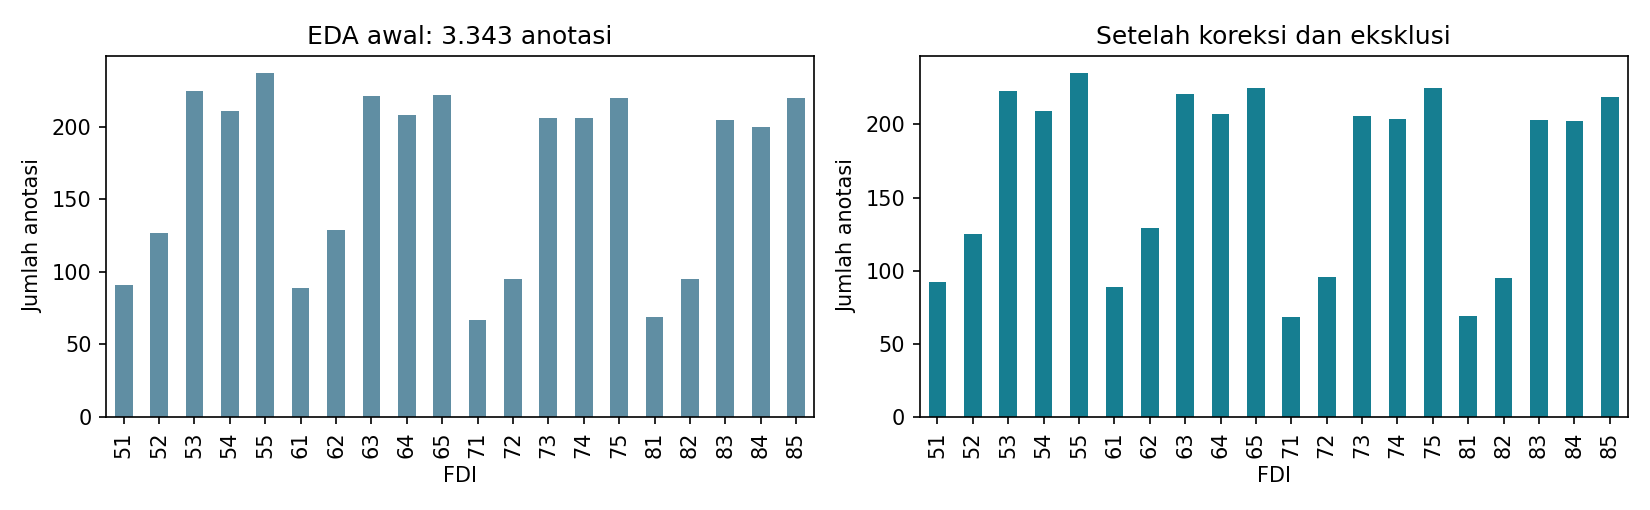

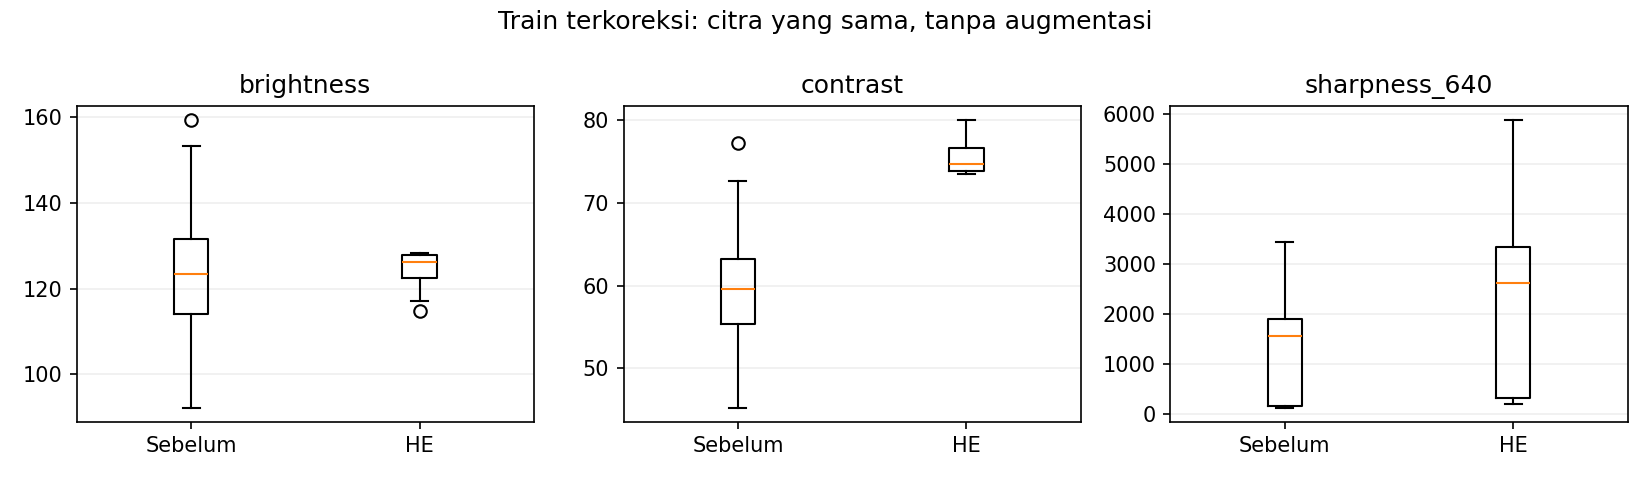

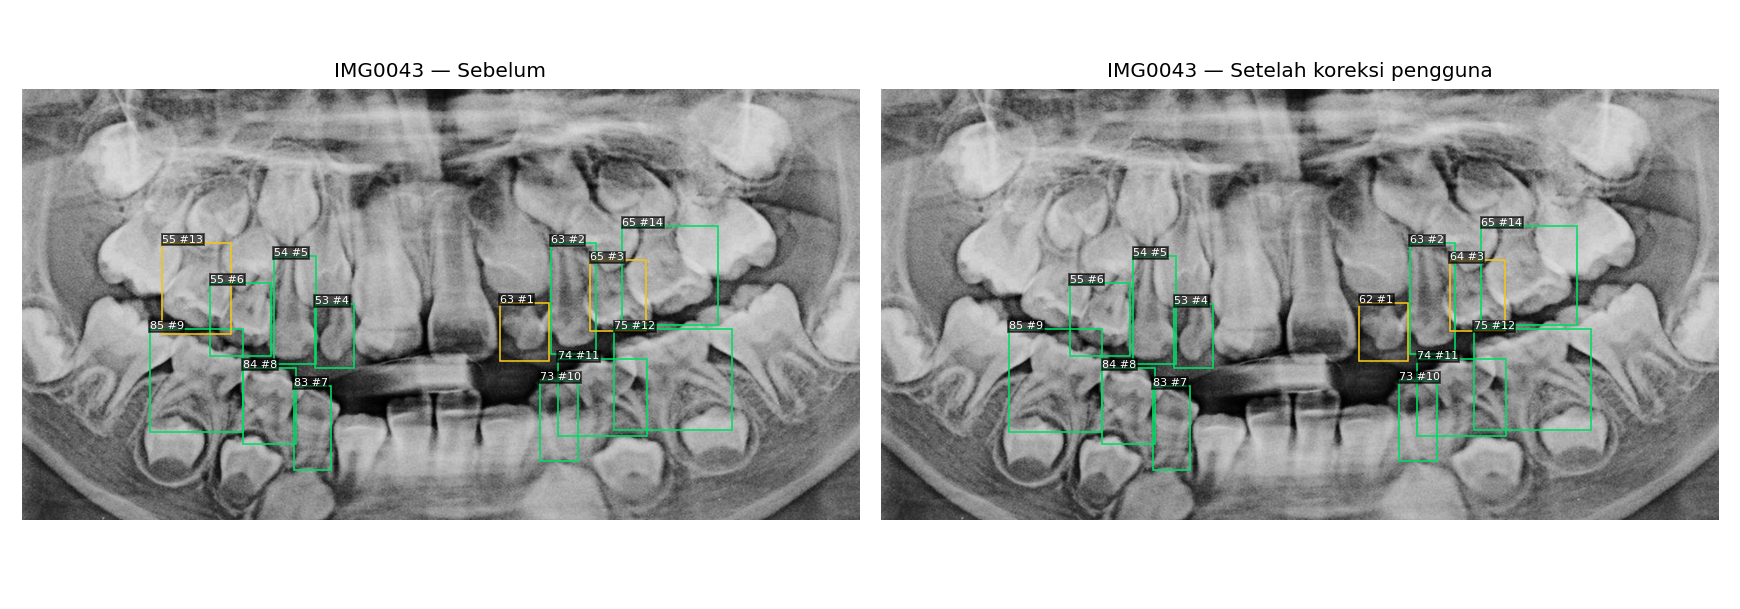

In [14]:
from IPython.display import Image as DisplayImage
display(pd.read_csv(TABEL_UTS/'ringkasan_akhir.csv'))
display(pd.read_csv(TABEL_UTS/'deskriptif_file_akhir.csv'))
display(DisplayImage(filename=str(UTS_OUT/'grafik'/'EDA_awal_akhir_FDI.png')))
display(DisplayImage(filename=str(UTS_OUT/'grafik'/'before_after_train.png')))
display(DisplayImage(filename=str(UTS_OUT/'overlay_koreksi'/'IMG0043_sebelum_sesudah.png')))

## 9 Verifikasi akhir dan rencana penelitian
Dataset terkoreksi tidak membuktikan semua anotasi sempurna; koreksi terbatas pada daftar review. Rencana berikutnya adalah membandingkan YOLO11n/s/m/l/x, menyesuaikan epoch, optimizer dan hyperparameter pada validation, lalu fine-tuning. Test digunakan pada evaluasi akhir. Kappa memerlukan unit penilaian dan pencocokan objek yang jelas, bukan dihitung langsung dari daftar box yang belum dipasangkan.

In [15]:
assert summary_uts['n_primary']==252
assert summary_uts['n_primary_boxes']==3342
assert summary_uts['final_files']==602
assert summary_uts['final_boxes']==7954
assert set(export_uts[export_uts.split!='train'].brightness_factor)=={1.}
print('252 citra; 3.342 anotasi asli terkoreksi; 602 file dan 7.954 anotasi hasil augmentasi train.')
print('Semua cell selesai dijalankan.')
completion={'status':'complete','images':252,'original_annotations_corrected':3342,'files':602,'annotations_augmented':7954,'manifest_sha256':hashlib.sha256((UTS_OUT/'dataset_terkoreksi'/'manifest.csv').read_bytes()).hexdigest()}
(UTS_OUT/'RUN_COMPLETE.json').write_text(json.dumps(completion,indent=2),encoding='utf-8')
print('Notebook 01 selesai. Dataset siap dibaca otomatis oleh notebook 02:',UTS_OUT/'dataset_terkoreksi')


252 citra; 3.342 anotasi asli terkoreksi; 602 file dan 7.954 anotasi hasil augmentasi train.
Semua cell selesai dijalankan.
Notebook 01 selesai. Dataset siap dibaca otomatis oleh notebook 02: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_analisis/dataset_terkoreksi


In [16]:
# PRAKTIK: ubah parameter IQR 1,5 menjadi 3,0
# Menggunakan citra train asli, bukan file hasil augmentasi.

import pandas as pd
from scipy.stats import binomtest
from IPython.display import display

kualitas = pd.read_csv(
    UTS_OUT / "tabel" / "kualitas_berpasangan.csv"
)
train = kualitas[kualitas["split"] == "train"].copy()

hasil = []

for k in [1.5, 3.0]:
    citra_berflag = pd.Series(False, index=train.index)
    jumlah_flag = 0

    # Batas IQR dihitung terpisah untuk setiap sumber.
    for sumber, grup in train.groupby("source"):
        for metrik in ["brightness", "contrast", "sharpness_640"]:
            nilai = grup[f"{metrik}_before"]

            Q1, Q3 = nilai.quantile([0.25, 0.75])
            IQR = Q3 - Q1

            batas_bawah = Q1 - k * IQR
            batas_atas = Q3 + k * IQR

            flag = (nilai < batas_bawah) | (nilai > batas_atas)

            jumlah_flag += int(flag.sum())
            citra_berflag.loc[grup.index] |= flag

    # Pengeluaran hanya untuk sensitivitas.
    # Dataset utama tidak diubah.
    dianalisis = train.loc[~citra_berflag].copy()

    ringkasan = {
        "Koefisien IQR": k,
        "Jumlah flag metrik": jumlah_flag,
        "Citra berflag": int(citra_berflag.sum()),
        "Citra dianalisis": len(dianalisis),
    }

    for metrik in ["contrast", "sharpness_640"]:
        dianalisis["delta"] = (
            dianalisis[f"{metrik}_after"]
            - dianalisis[f"{metrik}_before"]
        )

        # Versi dari kelompok asal yang sama tidak dihitung independen.
        delta = dianalisis.groupby("group_id")["delta"].median()
        tidak_nol = delta[delta != 0]

        ringkasan[f"Median delta {metrik}"] = delta.median()
        ringkasan[f"p uji tanda {metrik}"] = (
            binomtest(
                int((tidak_nol > 0).sum()),
                len(tidak_nol),
                p=0.5,
                alternative="greater",
            ).pvalue
            if len(tidak_nol) else float("nan")
        )

    hasil.append(ringkasan)

hasil_praktik = pd.DataFrame(hasil)
display(hasil_praktik)

lokasi = UTS_OUT / "tabel" / "praktik_parameter_IQR_1_5_vs_3.csv"
hasil_praktik.to_csv(lokasi, index=False)

print("Hasil tersimpan:", lokasi)
print("Dataset utama dan label tidak diubah.")

,Koefisien IQR,Jumlah flag metrik,Citra berflag,Citra dianalisis,Median delta contrast,p uji tanda contrast,Median delta sharpness_640,p uji tanda sharpness_640
0,1.5,14,12,163,16.643370,2.189529e-47,1067.898502,2.189529e-47
1,3.0,3,3,172,16.432231,1.402667e-47,1013.923832,8.552847e-50


Hasil tersimpan: /content/drive/MyDrive/1226800011_Aprilia_UjianEDA_Revisi/hasil_analisis/tabel/praktik_parameter_IQR_1_5_vs_3.csv
Dataset utama dan label tidak diubah.
